# Data Golf 2026: how did 13 teams answer the same 18 questions?

**Purpose.** Compare the final submissions from the Data Golf 2026 Kaggle competition, find where teams agreed and where they diverged, and pick a few findings for a lightning talk at a SNOMED CT conference.

**The competition in one paragraph.** Teams answered 18 yes/no clinical questions for each of 279,912 synthetic patient encounters coded in SNOMED CT (AU editions 2021 to 2026). They used FHIR terminology services and ECL. The official score was the unweighted mean of per-question F1 (macro F1). Ground truth comes from the competition's `solution.csv`.

**How to read this notebook.** Each step has a short note on what was done and why, then the code, then (after the code) what it showed. Charts appear inline and are saved to `outputs/` as separate images for slides.

**Conventions**
- Correctness is defined only by the competition's solution file. SNOMED CT's own modelling is not treated as ground truth. Where a split looks like a genuine modelling ambiguity, we say so rather than pick a side.
- Fifteen submissions were received. The two lowest-ranked (Teams 14 and 15) are partial submissions: they appear in the validation and leaderboard tables and are left out of every later step. Set `EXCLUDE_BOTTOM = 0` to keep them.
- Teams are labelled **Team 1 to Team 15** by recomputed rank. No chart or table names a team. The last cell reveals the podium. The Kaggle rules promised that nothing identifying participants would appear in the Expo presentation, so please keep it that way for the rest.
- Placings are **recomputed here** from the submissions (unweighted macro F1 over all rows). They are not the Kaggle leaderboard. If the official order differs, set `TEAM_ORDER` in the setup cell.
- The organisers' expected difficulty (1 easiest to 6 hardest) comes from `Question_Rationale.md`. These are pre-event expectations, not measured results.
- Spelling follows Australian English.

**Requirements.** Python 3.10+, `numpy`, `pandas`, `matplotlib`, `scipy`. Run from the `post-event analysis` folder. The notebook reads `submissions/*.csv`, `Question_Rationale.md`, `../solution.csv`, `../Questions.md` and `../TrainingDataSet.csv`.

## 0. Setup

In [1]:
import os
import re
import glob
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr, pearsonr, kendalltau

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 70)

# ---- paths (relative to the 'post-event analysis' folder) ----
SUBMISSIONS_DIR = "submissions"
SOLUTION_CSV = "../solution.csv"
TRAINING_CSV = "../TrainingDataSet.csv"
QUESTIONS_MD = "../Questions.md"
RATIONALE_MD = "Question_Rationale.md"      # organiser's expected difficulty (1 easiest to 6 hardest)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

QS = [f"Q{i}" for i in range(1, 19)]
ID_COL = "Episode Number"

# ---- optional inputs ----
# Partial submissions: drop this many of the lowest-ranked teams from every analysis after the leaderboard.
# They stay in the validation table and the leaderboard so the reason is visible. Set to 0 to keep all teams.
EXCLUDE_BOTTOM = 2
# Optional official placings: a list of submission file names (without .csv), best first.
TEAM_ORDER = None
PODIUM_NAMED = 0            # how many top teams are shown by name in charts and tables (the final cell reveals the podium)

# ---- thresholds for the row-level analysis (shares of the voting teams) ----
MISCONCEPTION_SHARE = 2 / 3  # at least this share of teams give the same WRONG answer
SPLIT_SHARE = (1 / 3, 2 / 3)  # share of teams saying True lies in this range (and not a misconception)
TOP_N_SENSITIVITY = 10       # robustness check: repeat the key results using only the top-N teams
MISMATCH_GAP = 6             # flag a question when expected and observed difficulty ranks differ by this many places

# ---- palette (validated: blue/orange/aqua pass the all-pairs colour-vision checks, light surface) ----
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BLUE = "#2a78d6"
BLUE_DK = "#184f95"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
RED = "#e34948"
SEQ_BLUE = [SURFACE, "#cde2fb", "#6da7ec", "#256abf", "#0d366b"]

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 16,
    "axes.titlesize": 22,
    "axes.labelsize": 16,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "text.color": INK,
    "axes.labelcolor": INK2,
    "xtick.color": INK2,
    "ytick.color": INK2,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
SLIDE = (13.33, 7.5)         # 16:9 slide

# ---- question text from the competition's own list ----
QTEXT = {}
for line in open(QUESTIONS_MD, encoding="utf-8"):
    m = re.match(r"\|\s*(Q\d+)\s*\|\s*(.+?)\s*\|\s*$", line)
    if m:
        QTEXT[m.group(1)] = m.group(2)
assert list(QTEXT) == QS, "Questions.md does not list Q1..Q18 in order"

# ---- the organiser's expected difficulty and main skill per question ----
DIFFICULTY, SKILL, RATIONALE_TRUE = {}, {}, {}
for line in open(RATIONALE_MD, encoding="utf-8"):
    m = re.match(r"^\|\s*(Q\d+)\s*\|[^|]*\|\s*([^|]+?)\s*\|\s*(\d)\s*\|\s*([\d,]+)\s*\|\s*$", line)
    if m:
        DIFFICULTY[m.group(1)] = int(m.group(3))
        SKILL[m.group(1)] = m.group(2)
        RATIONALE_TRUE[m.group(1)] = int(m.group(4).replace(",", ""))
assert list(DIFFICULTY) == QS, "Question_Rationale.md summary table does not list Q1..Q18 in order"
assert set(DIFFICULTY.values()) <= set(range(1, 7)), "difficulty values should be 1 to 6"

# Short labels for charts (condensed from QTEXT; no extra clinical content added)
SHORT = {
    "Q1": "Female",
    "Q2": "BMI 30+ and chol/HDL > 5",
    "Q3": "Healthy / no current problems",
    "Q4": "Hyperthyroidism (clinical note)",
    "Q5": "Osteoarthritis in 2024",
    "Q6": "ACE inhibitor",
    "Q7": "Cardiac (digitalis) glycoside",
    "Q8": "Fungal foot infection",
    "Q9": "More than one paracetamol product",
    "Q10": "Bilateral condition",
    "Q11": "Female 15-49 on methotrexate",
    "Q12": "Pregnant + teratogenic medicine",
    "Q13": "OA/RA + oral NSAID + eGFR < 60",
    "Q14": "Open wound, upper limb (not fingers/thumb)",
    "Q15": "Pregnant + fasting glucose >= 5.1",
    "Q16": "Non-Streptococcal bacterial joint infection",
    "Q17": "Oral iron supplement",
    "Q18": "Mineral supplement (not Na/K/Cl)",
}

pd.DataFrame({"Criterion": QTEXT}).rename_axis("Question")

,Criterion
Question,
Q1,Patients with female as their recorded sex.
Q2,Patients with a BMI of 30 or more and a total cholesterol to HDL r...
Q3,Patients documented as being healthy or free of current problems.
Q4,Patients with hyperthyroidism according to their clinical note.
Q5,Patients with osteoarthritis in 2024.
Q6,Patients taking an ACE inhibitor.
Q7,Patients taking a product containing a cardiac (digitalis) glycoside.
Q8,Patients with a fungal foot infection.
Q9,Patients taking more than one product that contains paracetamol.


## 1. Load and validate

**What and why.** Every submission is read into one boolean array shaped `[team, question, patient]`. Before anything else we check that each file covers the same patients as the solution file, uses clean True/False values, and has no missing cells. Problems are reported, never silently dropped.

Known quirks handled by the loader: values arrive as `TRUE`, `True` or `true`; one file starts with a byte-order mark; one has a quoted header. Teams are then ranked by recomputed macro F1 and relabelled, so no later output needs file names.

In [2]:
BOOL_MAP = {"true": True, "false": False}


def read_csv_clean(path):
    """Read a CSV as text, tolerating a BOM and quoted headers."""
    with open(path, "rb") as fh:
        has_bom = fh.read(3) == b"\xef\xbb\xbf"
    df = pd.read_csv(path, encoding="utf-8-sig", dtype=str)
    df.columns = [c.strip().strip('"') for c in df.columns]
    return df, has_bom


def to_bool(series):
    mapped = series.str.strip().str.lower().map(BOOL_MAP)
    n_bad = int(mapped.isna().sum())
    if n_bad:
        raise ValueError(f"{n_bad} cells are not True/False")
    return mapped.to_numpy(dtype=bool)


# ---- ground truth ----
sol, _ = read_csv_clean(SOLUTION_CSV)
sol_ids = sol[ID_COL].astype(int).to_numpy()
N = len(sol_ids)
Y = np.stack([to_bool(sol[q]) for q in QS])               # [question, patient]
IS_PUBLIC = (sol["Usage"].str.strip().str.lower() == "public").to_numpy()
assert len(set(sol_ids)) == N, "duplicate IDs in the solution"
mismatch = {q: (RATIONALE_TRUE[q], int(Y[i].sum())) for i, q in enumerate(QS) if RATIONALE_TRUE[q] != int(Y[i].sum())}
assert not mismatch, f"True counts in Question_Rationale.md differ from solution.csv: {mismatch}"

# ---- submissions ----
files = sorted(glob.glob(os.path.join(SUBMISSIONS_DIR, "*.csv")))
stems, preds, checks = [], [], []
for path in files:
    stem = os.path.splitext(os.path.basename(path))[0]
    df, has_bom = read_csv_clean(path)
    cols_ok = list(df.columns) == [ID_COL] + QS
    raw_forms = sorted(set(df[QS].stack().str.strip().unique()))
    ids = df[ID_COL].astype(int).to_numpy()
    same_order = bool(np.array_equal(ids, sol_ids))
    same_set = set(ids) == set(sol_ids)
    n_dupes = int(len(ids) - len(set(ids)))
    n_missing = len(set(sol_ids) - set(ids))
    n_extra = len(set(ids) - set(sol_ids))
    n_blank = int(df[QS].isna().sum().sum())
    if not cols_ok:
        raise ValueError(f"unexpected columns in a submission: {list(df.columns)[:3]}...")
    if n_dupes or n_missing or n_extra:
        raise ValueError(
            f"ID mismatch: dupes={n_dupes} missing={n_missing} extra={n_extra}. "
            "Decide how to handle it explicitly before continuing."
        )
    if not same_order:  # same patients, different order: align explicitly and say so
        df = df.set_index(df[ID_COL].astype(int)).loc[sol_ids].reset_index(drop=True)
    arr = np.stack([to_bool(df[q]) for q in QS])
    stems.append(stem)
    preds.append(arr)
    checks.append(dict(rows=len(ids), ids_match=same_set, same_order=same_order,
                       duplicates=n_dupes, blank_cells=n_blank, bom=has_bom,
                       spellings=", ".join(raw_forms)))

P = np.stack(preds)                                        # [team, question, patient]
T = P.shape[0]
print(f"{T} submissions x {len(QS)} questions x {N:,} patients. Public rows: {IS_PUBLIC.sum():,}; private rows: {(~IS_PUBLIC).sum():,}.")


def f1_np(y, p):
    """Binary F1 for the positive class (0.0 when there are no true positives, as scikit-learn does)."""
    tp = np.count_nonzero(y & p)
    fp = np.count_nonzero(~y & p)
    fn = np.count_nonzero(y & ~p)
    return 0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)


F1 = np.array([[f1_np(Y[q], P[t, q]) for q in range(len(QS))] for t in range(T)])   # [team, question]
macro = F1.mean(axis=1)

# ---- rank teams (recomputed) and reorder everything so team index k is rank k+1 ----
if TEAM_ORDER:
    order = [stems.index(s) for s in TEAM_ORDER]
    assert sorted(order) == list(range(T)), "TEAM_ORDER must list every submission exactly once"
else:
    order = list(np.argsort(-macro, kind="stable"))
FILES = [stems[i] for i in order]          # real names: keep out of any output
P = P[order]
F1 = F1[order]
macro = macro[order]
checks = [checks[i] for i in order]

TEAMS = [f"Team {k + 1}" for k in range(T)]


def label(k, named=True):
    """Chart label for team index k. Only the podium may carry a real name."""
    if named and k < PODIUM_NAMED:
        return f"Team {k + 1}: {FILES[k]}"
    return TEAMS[k]


FORBIDDEN = [f for f in FILES[PODIUM_NAMED:]]   # names that must never appear in outputs

validation = pd.DataFrame(checks, index=TEAMS)
validation

15 submissions x 18 questions x 279,912 patients. Public rows: 139,956; private rows: 139,956.


,rows,ids_match,same_order,duplicates,blank_cells,bom,spellings
Team 1,279912,True,True,0,0,False,"false, true"
Team 2,279912,True,True,0,0,False,"False, True"
Team 3,279912,True,True,0,0,False,"False, True"
Team 4,279912,True,True,0,0,False,"False, True"
Team 5,279912,True,True,0,0,False,"False, True"
Team 6,279912,True,True,0,0,False,"False, True"
Team 7,279912,True,True,0,0,False,"False, True"
Team 8,279912,True,True,0,0,False,"False, True"
Team 9,279912,True,True,0,0,False,"False, True"
Team 10,279912,True,True,0,0,False,"False, True"


**Validation result.** The table above is the evidence: row counts, ID matches, duplicates, blank cells and the spellings of True/False found in each file. The loader stops on any ID mismatch rather than dropping rows. The cell below turns that into one explicit statement.

**Finding.** All 15 files cover the same 279,912 Episode Numbers as the solution file, in the same order, with no duplicates or blanks. Nothing was dropped or realigned. The loader did have to handle three spellings of True/False and one file with a byte-order mark. Confidence: high.

In [3]:
assert validation["ids_match"].all() and (validation["rows"] == N).all()
assert (validation["duplicates"] == 0).all() and (validation["blank_cells"] == 0).all()
print(f"All {T} submissions cover the same {N:,} Episode Numbers as the solution file, with no duplicates or blanks.")
print("Files whose rows were in a different order (aligned by ID):", int((~validation["same_order"]).sum()))

All 15 submissions cover the same 279,912 Episode Numbers as the solution file, with no duplicates or blanks.
Files whose rows were in a different order (aligned by ID): 0


### Recomputed leaderboard

**What and why.** We score every team with the competition's metric (unweighted mean of per-question F1) over all rows, and also over the public and private halves. The ranking is used to order teams in every later chart. It is **recomputed**, so confirm it against the official leaderboard before presenting it as final.

In [4]:
def macro_f1(mask):
    return np.array([np.mean([f1_np(Y[q][mask], P[t, q][mask]) for q in range(len(QS))]) for t in range(T)])


all_rows = np.ones(N, dtype=bool)
board = pd.DataFrame({
    "Team": [label(k) for k in range(T)],
    "Macro F1 (all rows)": macro,
    "Public": macro_f1(IS_PUBLIC),
    "Private": macro_f1(~IS_PUBLIC),
    "Weakest question F1": F1.min(axis=1),
    "Questions with F1 >= 0.99": (F1 >= 0.99).sum(axis=1),
    "Questions answered all False": [int((~P[t]).all(axis=1).sum()) for t in range(T)],
    "Share of answers True (all cells)": P.reshape(T, -1).mean(axis=1),
    "In analysis": ["yes" if k < T - EXCLUDE_BOTTOM else "no (partial)" for k in range(T)],
}, index=range(1, T + 1)).rename_axis("Rank")

# From here on, only the analysed teams are used. FILES stays complete so FORBIDDEN still covers every name.
T_ALL = T
P_ALL, F1_ALL, macro_ALL = P, F1, macro      # full 15-team arrays, used only to show what excluding the partial teams changed
if EXCLUDE_BOTTOM:
    T = T_ALL - EXCLUDE_BOTTOM
    P, F1, macro, TEAMS = P[:T], F1[:T], macro[:T], TEAMS[:T]
print(f"Leaderboard shows all {T_ALL} teams. Analysis from here on uses the top {T}.")
board.round(4)

Leaderboard shows all 15 teams. Analysis from here on uses the top 13.


,Team,Macro F1 (all rows),Public,Private,Weakest question F1,Questions with F1 >= 0.99,Questions answered all False,Share of answers True (all cells),In analysis
Rank,,,,,,,,,
1,Team 1,0.9922,0.9918,0.9926,0.9426,14,0,0.0575,yes
2,Team 2,0.9914,0.9919,0.9909,0.9503,14,0,0.0574,yes
3,Team 3,0.9898,0.9906,0.9890,0.8972,14,0,0.0573,yes
4,Team 4,0.9685,0.9681,0.9689,0.8110,11,0,0.0577,yes
5,Team 5,0.9626,0.9620,0.9633,0.7219,12,0,0.0578,yes
6,Team 6,0.9497,0.9502,0.9493,0.5836,12,0,0.0574,yes
7,Team 7,0.9455,0.9455,0.9455,0.6510,10,0,0.0586,yes
8,Team 8,0.9328,0.9351,0.9306,0.6271,9,0,0.0562,yes
9,Team 9,0.9243,0.9266,0.9218,0.3956,9,0,0.0570,yes


**Finding.**
- The top three teams finish within 0.0024 of each other (macro F1 0.9922, 0.9914 and 0.9898). Teams 1 and 2 swap places between the public and private halves, so treat them as tied.
- Teams 14 and 15 look like partial submissions rather than weaker methods. Team 14 answered seven of the 18 questions as all False. Team 15 answered True on about 40% of all cells, against about 6% for every other team, which looks like random fill. The last column of the table marks both "no (partial)".
- They are left out of every step after this one. With them in, mean percent agreement between teams was about 0.93 on most questions. With them out it is above 0.98 on every question (lowest 0.988, on Q18). They also create apparent majorities that only reflect their columns. The validation and leaderboard tables keep all 15 so the reason stays visible, and step 2 shows the before and after side by side.
- Confidence: high for the table (computed from the files). The ranking is recomputed, not the official leaderboard. Calling Teams 14 and 15 "partial" is our reading of the patterns above; the organisers' records may say more.

## 2. Question-level agreement

**What and why.** For every question we compare all 78 pairs of the 13 analysed teams using two measures:

- **Percent agreement**: the share of patients on which two teams gave the same answer.
- **Cohen's kappa**: agreement beyond what chance would produce.

We use both because most questions have a rare "True" class. For Q7 only 239 of 279,912 patients are True, so two teams that disagree on every True patient still agree on over 99.9% of rows. Percent agreement alone would hide that. Kappa is the primary ranking measure for that reason.

We also compute each team's F1 against ground truth, and rank the questions from most to least contested (lowest mean pairwise kappa first).

In [5]:
def pairwise_stats(Pq):
    """Pairwise percent agreement and Cohen's kappa for one question. Pq: [team, patient] bool."""
    X = Pq.astype(np.float32)
    both = X @ X.T                                   # counts of (True, True); exact below 2**24
    n1 = np.diag(both)
    n_agree = both + (N - n1[:, None] - n1[None, :] + both)
    po = n_agree / N
    p1 = n1 / N
    pe = p1[:, None] * p1[None, :] + (1 - p1[:, None]) * (1 - p1[None, :])
    with np.errstate(divide="ignore", invalid="ignore"):
        kappa = np.where(pe < 1, (po - pe) / (1 - pe), np.nan)   # undefined if everyone answers one class
    return po, kappa


AGR = np.zeros((len(QS), T, T))
KAP = np.zeros((len(QS), T, T))
for qi in range(len(QS)):
    AGR[qi], KAP[qi] = pairwise_stats(P[:, qi, :])

IU = np.triu_indices(T, 1)


def contest_table(team_idx=None):
    sel = np.arange(T) if team_idx is None else np.asarray(team_idx)
    iu = np.triu_indices(len(sel), 1)
    rows = []
    for qi, q in enumerate(QS):
        a = AGR[qi][np.ix_(sel, sel)][iu]
        k = KAP[qi][np.ix_(sel, sel)][iu]
        f = F1[sel, qi]
        rows.append(dict(Question=q, Criterion=SHORT[q], expected_difficulty=DIFFICULTY[q], truth_true=int(Y[qi].sum()),
                         mean_agreement=a.mean(), mean_kappa=np.nanmean(k),
                         mean_F1=f.mean(), F1_sd=f.std(), F1_min=f.min(), F1_max=f.max(),
                         teams_F1_ge_099=int((f >= 0.99).sum())))
    return pd.DataFrame(rows).set_index("Question")


contest = contest_table().sort_values("mean_kappa")
contest["contested_rank"] = np.arange(1, len(QS) + 1)

# robustness: rank again using only the top-N teams (the weakest submissions can dominate a pooled kappa)
sens = contest_table(range(TOP_N_SENSITIVITY)).sort_values("mean_kappa")
sens_rank = pd.Series(np.arange(1, len(QS) + 1), index=sens.index)
contest[f"rank_top{TOP_N_SENSITIVITY}_teams"] = sens_rank.reindex(contest.index)
contest["rank_shift"] = contest[f"rank_top{TOP_N_SENSITIVITY}_teams"] - contest["contested_rank"]
contest.round(4)

,Criterion,expected_difficulty,truth_true,mean_agreement,mean_kappa,mean_F1,F1_sd,F1_min,F1_max,teams_F1_ge_099,contested_rank,rank_top10_teams,rank_shift
Question,,,,,,,,,,,,,
Q12,Pregnant + teratogenic medicine,6,347,0.9986,0.4565,0.6273,0.2724,0.0000,0.9913,1,1,1,0
Q15,Pregnant + fasting glucose >= 5.1,4,461,0.9987,0.5811,0.6813,0.2332,0.0172,0.9538,0,2,2,0
Q18,Mineral supplement (not Na/K/Cl),5,14498,0.9876,0.8428,0.8965,0.0970,0.7427,0.9946,1,3,3,0
Q16,Non-Streptococcal bacterial joint infection,3,1472,0.9984,0.8906,0.9393,0.1255,0.5665,1.0000,5,4,6,2
Q13,OA/RA + oral NSAID + eGFR < 60,4,1819,0.9990,0.8995,0.9069,0.1014,0.5825,0.9646,0,5,7,2
Q17,Oral iron supplement,3,10649,0.9947,0.9134,0.9549,0.0814,0.7634,1.0000,8,6,4,-2
Q4,Hyperthyroidism (clinical note),4,10859,0.9932,0.9253,0.9363,0.0686,0.7769,1.0000,4,7,5,-2
Q5,Osteoarthritis in 2024,3,3819,0.9985,0.9382,0.9451,0.0692,0.7099,0.9995,1,8,9,1
Q9,More than one paracetamol product,4,3230,0.9993,0.9621,0.9812,0.0642,0.7589,1.0000,12,9,11,2


**Finding.**
- Q1, Q2 and Q7 are not contested. Q1 and Q7 are perfect for every team, and Q2 scores F1 0.9997 or better. Q7 only looked contested when the partial submissions were included.
- Q12 and Q15, the two pregnancy questions, are the most contested by a wide margin (mean kappa 0.46 and 0.58). Mean F1 is only 0.63 and 0.68. No team reached F1 0.99 on Q15, and only one did on Q12.
- Q18 is third (kappa 0.84, mean F1 0.90), followed by Q16 and Q13 (kappa 0.89 and 0.90). Below Q5, every question has mean kappa above 0.96.
- Using only the top 10 teams moves ranks by at most five places (column `rank_shift`). The top three do not move.
- Confidence: high for Q12, Q15 and Q18. Medium below that, where kappa differences are small (0.92 to 0.99) and ranks move by up to five places depending on which teams are included.

### What did excluding the two partial submissions change?

**What and why.** To show whether dropping Teams 14 and 15 was justified, we repeat the question-level comparison with all 15 teams and set it beside the 13-team version. For each question we compare mean percent agreement, mean kappa, mean F1 and the "most contested" rank (1 = most contested).

In [6]:
if EXCLUDE_BOTTOM:
    AGR_ALL = np.zeros((len(QS), T_ALL, T_ALL))
    KAP_ALL = np.zeros((len(QS), T_ALL, T_ALL))
    for qi in range(len(QS)):
        AGR_ALL[qi], KAP_ALL[qi] = pairwise_stats(P_ALL[:, qi, :])
    iu15 = np.triu_indices(T_ALL, 1)
    c13 = contest.reindex(QS)
    impact = pd.DataFrame({
        "Criterion": [SHORT[q] for q in QS],
        "agreement_15": [AGR_ALL[i][iu15].mean() for i in range(len(QS))],
        f"agreement_{T}": c13["mean_agreement"],
        "kappa_15": [np.nanmean(KAP_ALL[i][iu15]) for i in range(len(QS))],
        f"kappa_{T}": c13["mean_kappa"],
        "mean_F1_15": F1_ALL.mean(axis=0),
        f"mean_F1_{T}": c13["mean_F1"],
    }, index=QS)
    impact["contested_rank_15"] = impact["kappa_15"].rank(method="min").astype(int)
    impact[f"contested_rank_{T}"] = impact[f"kappa_{T}"].rank(method="min").astype(int)
    impact["rank_change"] = impact["contested_rank_15"] - impact[f"contested_rank_{T}"]      # positive = looks less contested without them
    impact = impact.sort_values(f"contested_rank_{T}")
    display(impact.round(4))

    a15, a13 = impact["agreement_15"], impact[f"agreement_{T}"]
    print(f"Mean percent agreement between teams: median across questions {a15.median():.3f} with all 15, {a13.median():.3f} with {T}.")
    print(f"Questions with mean agreement below 0.95: {int((a15 < 0.95).sum())} with all 15, {int((a13 < 0.95).sum())} with {T}.")
    print(f"Questions where mean F1 changes by more than 0.05 when the two are removed: "
          f"{', '.join(impact.index[(impact[f'mean_F1_{T}'] - impact['mean_F1_15']).abs() > 0.05])}")
    big = impact[impact["rank_change"].abs() >= 4]
    print("Questions whose contested rank moves by 4 or more places:",
          "; ".join(f"{q} ({r.contested_rank_15} -> {r[f'contested_rank_{T}']})" for q, r in big.iterrows()))
else:
    print("EXCLUDE_BOTTOM is 0, so there is nothing to compare.")

,Criterion,agreement_15,agreement_13,kappa_15,kappa_13,mean_F1_15,mean_F1_13,contested_rank_15,contested_rank_13,rank_change
Q12,Pregnant + teratogenic medicine,0.9323,0.9986,0.3391,0.4565,0.5438,0.6273,1,1,0
Q15,Pregnant + fasting glucose >= 5.1,0.9322,0.9987,0.4316,0.5811,0.5906,0.6813,2,2,0
Q18,Mineral supplement (not Na/K/Cl),0.9187,0.9876,0.6261,0.8428,0.7833,0.8965,3,3,0
Q16,Non-Streptococcal bacterial joint infection,0.9314,0.9984,0.6616,0.8906,0.8147,0.9393,4,4,0
Q13,OA/RA + oral NSAID + eGFR < 60,0.9319,0.9990,0.6682,0.8995,0.7869,0.9069,5,5,0
Q17,Oral iron supplement,0.9278,0.9947,0.7776,0.9134,0.8847,0.9549,8,6,2
Q4,Hyperthyroidism (clinical note),0.9917,0.9932,0.9073,0.9253,0.9261,0.9363,16,7,9
Q5,Osteoarthritis in 2024,0.9322,0.9985,0.8166,0.9382,0.8846,0.9451,9,8,1
Q9,More than one paracetamol product,0.9327,0.9993,0.8362,0.9621,0.9186,0.9812,10,9,1
Q14,"Open wound, upper limb (not fingers/thumb)",0.9204,0.9961,0.7231,0.9733,0.8640,0.9862,6,10,-4


Mean percent agreement between teams: median across questions 0.933 with all 15, 0.999 with 13.
Questions with mean agreement below 0.95: 13 with all 15, 0 with 13.
Questions where mean F1 changes by more than 0.05 when the two are removed: Q12, Q15, Q18, Q16, Q13, Q17, Q5, Q9, Q14, Q11, Q6, Q8, Q10, Q7
Questions whose contested rank moves by 4 or more places: Q4 (16 -> 7); Q14 (6 -> 10); Q3 (15 -> 11); Q10 (7 -> 15)


**Finding.** Keeping Teams 14 and 15 gave several misleading impressions, which is why they are left out. The five most contested questions (Q12, Q15, Q18, Q16 and Q13) are the same, in the same order, either way, so the headline result does not depend on this choice. The details below do.
- **Disagreement was overstated.** The median of mean percent agreement across questions was 0.933 with all 15 teams and 0.999 with 13. Thirteen questions had mean agreement below 0.95 with all 15 teams, and none do with 13. Most of that apparent disagreement came from two columns, not from the other teams.
- **Some questions looked contested when they were not.** Q10 ranked 7th most contested with 15 teams and 15th with 13: every one of the 13 complete teams scored F1 0.995 or better. Q7 (mean kappa 0.87 to 1.00) and Q14 (6th to 10th) also changed.
- **One looked uncontested when it was not.** Q4 ranked 16th with 15 teams and 7th with 13. Its kappa barely moved (0.91 to 0.93) while the other questions' kappas rose a great deal, so the real disagreement among the complete teams (see Finding 1) had been hidden.
- **Difficulty was overstated.** Mean F1 changes by more than 0.05 on 14 of 18 questions. Q10 goes from 0.87 to 0.999 and Q14 from 0.86 to 0.99. This matters for step 3, because difficulty read off all 15 teams would look much higher than it was for teams that submitted complete answers.
- **Confidence: high** that the two submissions distort the comparison, since every number above is computed from the files. Calling them "partial" is still our judgement. Set `EXCLUDE_BOTTOM = 0` to see the notebook with them included.

### Chart A: where each team lost points

**What and why.** One cell per team and question showing how many F1 points the team lost against ground truth (1 minus F1). White means a perfect answer, so the eye goes straight to the failures. Columns run from the most contested question (left) to the least. Cells below F1 0.95 show their F1.

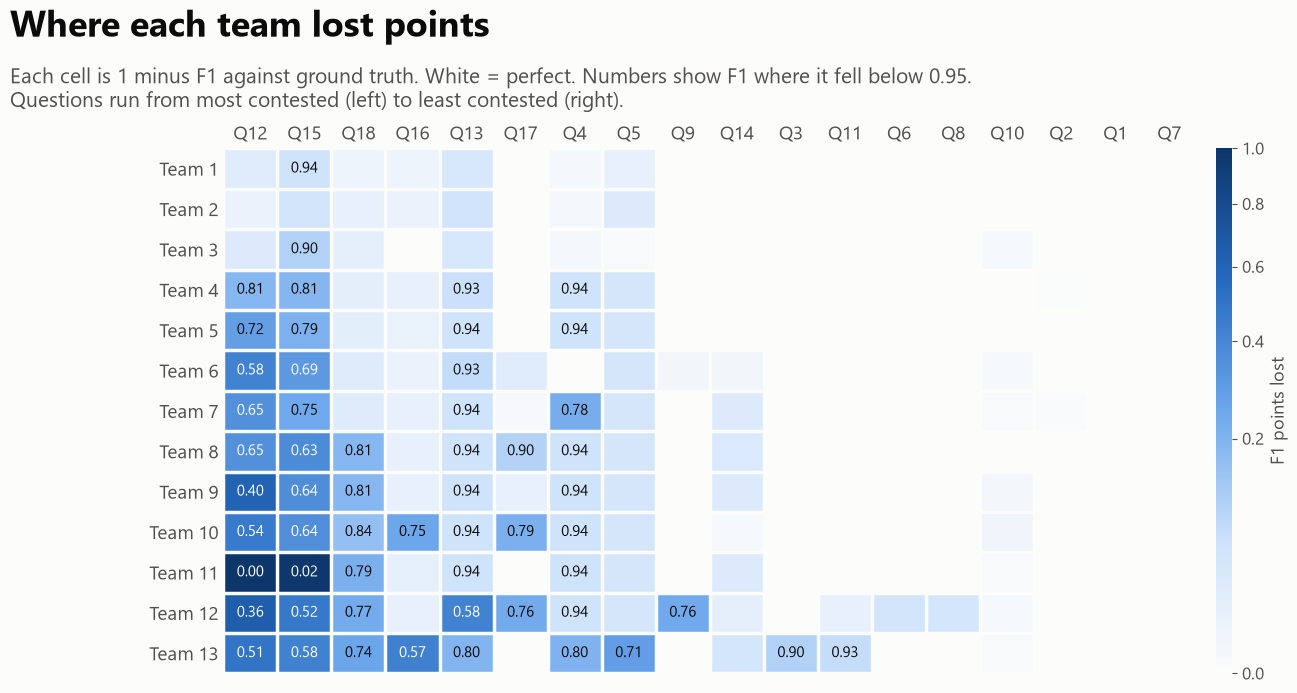

In [7]:
def save_fig(fig, name):
    """Save a slide-ready PNG after checking no non-podium team name appears in it."""
    texts = " ".join(t.get_text() for t in fig.findobj(mpl.text.Text)).lower()
    leaked = [n for n in FORBIDDEN if n.lower() in texts]
    assert not leaked, "A team name leaked into a chart"
    path = os.path.join(OUT, name)
    fig.savefig(path, dpi=200, facecolor=SURFACE)
    return path


def headline(fig, title, subtitle=None, y=0.965):
    fig.text(0.04, y, title, fontsize=26, fontweight="bold", color=INK, va="top")
    if subtitle:
        fig.text(0.04, y - 0.075, subtitle, fontsize=15, color=INK2, va="top")


col_order = [QS.index(q) for q in contest.index]          # most contested first
loss = 1 - F1[:, col_order]

fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(left=0.20, right=0.93, top=0.78, bottom=0.08)
cmap = LinearSegmentedColormap.from_list("loss", SEQ_BLUE)
norm = PowerNorm(gamma=0.5, vmin=0, vmax=1)
im = ax.imshow(loss, cmap=cmap, norm=norm, aspect="auto")
ax.set_xticks(range(len(QS)))
ax.set_xticklabels([contest.index[i] for i in range(len(QS))], fontsize=14)
ax.set_yticks(range(T))
ax.set_yticklabels([label(k) for k in range(T)], fontsize=14)
ax.xaxis.tick_top()
ax.set_xticks(np.arange(-.5, len(QS), 1), minor=True)
ax.set_yticks(np.arange(-.5, T, 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2.5)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
for r in range(T):
    for c in range(len(QS)):
        if F1[r, col_order[c]] < 0.95:
            dark = norm(loss[r, c]) > 0.55
            ax.text(c, r, f"{F1[r, col_order[c]]:.2f}", ha="center", va="center",
                    fontsize=11, color="white" if dark else INK)
cax = fig.add_axes([0.945, 0.08, 0.012, 0.70])
cb = fig.colorbar(im, cax=cax)
cb.set_label("F1 points lost", fontsize=13, color=INK2)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=12)
headline(fig, "Where each team lost points",
         "Each cell is 1 minus F1 against ground truth. White = perfect. Numbers show F1 where it fell below 0.95.\n"
         "Questions run from most contested (left) to least contested (right).")
path_a = save_fig(fig, "A_team_by_question_heatmap.png")
plt.show()

**Reading Chart A.** Teams 14 and 15 are not shown (partial submissions). Teams 1 to 3 are almost white across the board; their weakest cell is Team 3 on Q15 (F1 0.90). Teams 4 to 10 lose most of their points on the two pregnancy questions (F1 from 0.40 to 0.81), and most share a small loss on Q4 and Q13 (F1 about 0.94 each). Team 11 scored almost nothing on Q12 and Q15 (F1 0.00 and 0.02). Team 13 loses points on the most questions (nine cells below F1 0.95). Confidence: high.

### Chart B: the most contested questions

**What and why.** Questions ranked by how much teams disagreed with each other (1 minus mean pairwise kappa). The five most contested are highlighted. The text at the end of each bar gives the mean F1 against ground truth, so you can see whether disagreement also meant being wrong. Each bar also shows the organisers' expected difficulty from `Question_Rationale.md`.

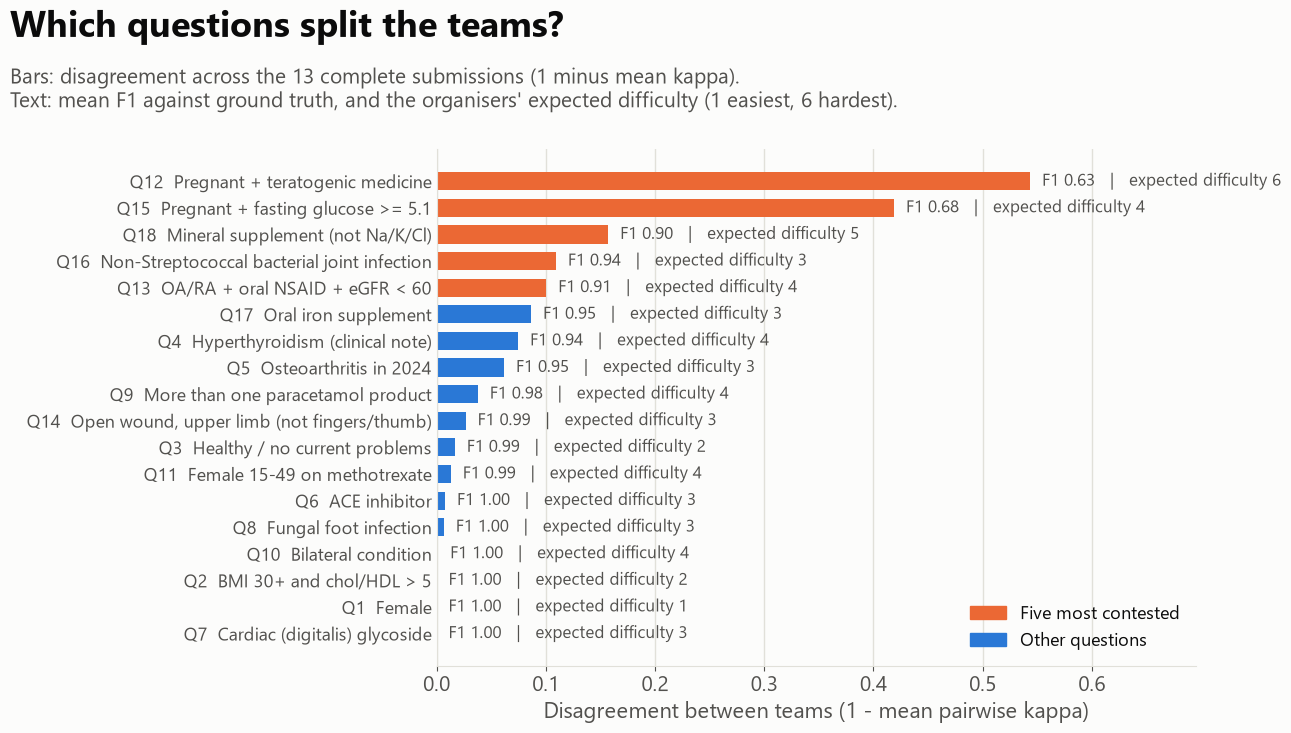

In [8]:
rank_df = contest.copy()
rank_df["contest"] = 1 - rank_df["mean_kappa"]
rank_df = rank_df.sort_values("contest", ascending=True)      # least contested at the bottom of the chart

fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(left=0.36, right=0.93, top=0.78, bottom=0.09)
y = np.arange(len(rank_df))
HILITE = 5
colors = [ORANGE if i >= len(rank_df) - HILITE else BLUE for i in range(len(rank_df))]
ax.barh(y, rank_df["contest"], color=colors, height=0.68)
ax.set_yticks(y)
ax.set_yticklabels([f"{q}  {SHORT[q]}" for q in rank_df.index], fontsize=13)
ax.set_xlabel("Disagreement between teams (1 - mean pairwise kappa)")
ax.xaxis.grid(True, color=GRID, linewidth=1)
ax.set_axisbelow(True)
xmax = rank_df["contest"].max()
ax.set_xlim(0, xmax * 1.28)
for i, (q, row) in enumerate(rank_df.iterrows()):
    txt = f"F1 {row['mean_F1']:.2f}   |   expected difficulty {DIFFICULTY[q]}"
    ax.text(row["contest"] + xmax * 0.02, i, txt, va="center", fontsize=12, color=INK2)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=ORANGE, label="Five most contested"), Patch(color=BLUE, label="Other questions")],
          loc="lower right", frameon=False, fontsize=13)
headline(fig, "Which questions split the teams?",
         f"Bars: disagreement across the {T} complete submissions (1 minus mean kappa).\n"
         "Text: mean F1 against ground truth, and the organisers' expected difficulty (1 easiest, 6 hardest).")
path_b = save_fig(fig, "B_contested_questions.png")
plt.show()

**Reading Chart B.** Q12, Q15 and Q18 stand clear of the rest. The two highest expected ratings, Q12 (6) and Q18 (5), are both among the three most contested. Q15 was rated 4. The next five bars (Q16, Q13, Q17, Q4 and Q5) are much shorter, and questions rated 3 or 4 appear all the way down the chart. Step 3 tests this properly.

## 3. Did the questions turn out as hard as the organisers expected?

**What and why.** Before the event the organisers rated each question from 1 (easiest) to 6 (hardest) in `Question_Rationale.md`. Here we compare those ratings with what happened. We use four measures of observed difficulty, all oriented so that a higher number means harder:

- **F1 lost**: 1 minus the mean F1 across teams.
- **Disagreement**: 1 minus the mean pairwise kappa between teams.
- **Spread**: the standard deviation of team F1.
- **Share of teams below F1 0.95**.

We report **Spearman** and **Kendall** rank correlations, because the ratings are ordinal and many questions share a rating (seven questions are rated 3, six are rated 4). A second set leaves out Q1 and Q2, the two questions that need no terminology work, to check that the easy end is not carrying the result. A third checks how far one question can move the answer: drop each question in turn and look at the range of Spearman values.

Then we rank questions by expected and observed difficulty and flag any that differ by 6 places or more.

In [9]:
dif = pd.Series(DIFFICULTY).reindex(QS)
ob = contest.reindex(QS)
hard = pd.DataFrame({
    "F1 lost (1 - mean F1)": 1 - ob["mean_F1"],
    "Disagreement (1 - mean kappa)": 1 - ob["mean_kappa"],
    "Spread (SD of team F1)": ob["F1_sd"],
    "Share of teams below F1 0.95": [(F1[:, i] < 0.95).mean() for i in range(len(QS))],
}, index=QS)

rows = []
for name, col in hard.items():
    rs = spearmanr(dif, col)
    kt = kendalltau(dif, col)
    keep = [q for q in QS if q not in ("Q1", "Q2")]
    rs16 = spearmanr(dif[keep], col[keep])
    loo = [spearmanr(dif.drop(q), col.drop(q)).statistic for q in QS]
    rows.append({"Observed difficulty measure": name,
                 "Spearman rho (18 questions)": rs.statistic, "p": rs.pvalue,
                 "Kendall tau-b": kt.statistic, "p (tau)": kt.pvalue,
                 "Spearman rho (without Q1, Q2)": rs16.statistic, "p (without Q1, Q2)": rs16.pvalue,
                 "rho range, drop one question": f"{min(loo):.2f} to {max(loo):.2f}"})
corr = pd.DataFrame(rows).set_index("Observed difficulty measure")
display(corr.round(3))

# the same check using only the top-10 teams (the lowest-ranked of the analysed teams can dominate pooled measures)
t10 = contest_table(range(TOP_N_SENSITIVITY)).reindex(QS)
rho10 = spearmanr(dif, 1 - t10["mean_F1"])
print(f"Using only the top {TOP_N_SENSITIVITY} teams: Spearman rho between expected difficulty and F1 lost = {rho10.statistic:.2f} (p = {rho10.pvalue:.3f}).")

,Spearman rho (18 questions),p,Kendall tau-b,p (tau),"Spearman rho (without Q1, Q2)","p (without Q1, Q2)","rho range, drop one question"
Observed difficulty measure,,,,,,,
F1 lost (1 - mean F1),0.667,0.002,0.565,0.003,0.548,0.028,0.60 to 0.76
Disagreement (1 - mean kappa),0.625,0.006,0.520,0.006,0.487,0.056,0.55 to 0.71
Spread (SD of team F1),0.586,0.011,0.474,0.012,0.431,0.095,0.50 to 0.67
Share of teams below F1 0.95,0.631,0.005,0.523,0.009,0.560,0.024,0.57 to 0.72


Using only the top 10 teams: Spearman rho between expected difficulty and F1 lost = 0.65 (p = 0.003).


In [10]:
# Rank both ways: 1 = hardest. Ties get the average rank.
cmp = pd.DataFrame({
    "criterion": [SHORT[q] for q in QS],
    "skill (organiser)": [SKILL[q] for q in QS],
    "expected_difficulty": dif,
    "F1_lost": hard["F1 lost (1 - mean F1)"],
}, index=QS)
cmp["expected_rank"] = cmp["expected_difficulty"].rank(ascending=False, method="average")
cmp["observed_rank"] = cmp["F1_lost"].rank(ascending=False, method="average")
cmp["harder_than_expected_by"] = cmp["expected_rank"] - cmp["observed_rank"]    # positive = harder than expected
cmp["flag"] = np.where(cmp["harder_than_expected_by"] >= MISMATCH_GAP, "HARDER than expected",
                       np.where(cmp["harder_than_expected_by"] <= -MISMATCH_GAP, "EASIER than expected", ""))
# how much does the result depend on the very hardest questions?
order_hard = cmp["F1_lost"].sort_values(ascending=False).index
for k in (1, 2, 3):
    keep = [q for q in QS if q not in order_hard[:k]]
    r = spearmanr(dif[keep], cmp.loc[keep, "F1_lost"])
    print(f"Without the {k} hardest by outcome ({', '.join(order_hard[:k])}): Spearman rho = {r.statistic:.2f} (p = {r.pvalue:.3f})")
cmp.sort_values("harder_than_expected_by", ascending=False).round(3)

Without the 1 hardest by outcome (Q12): Spearman rho = 0.60 (p = 0.011)
Without the 2 hardest by outcome (Q12, Q15): Spearman rho = 0.57 (p = 0.022)
Without the 3 hardest by outcome (Q12, Q15, Q18): Spearman rho = 0.47 (p = 0.079)


,criterion,skill (organiser),expected_difficulty,F1_lost,expected_rank,observed_rank,harder_than_expected_by,flag
Q16,Non-Streptococcal bacterial joint infection,Attributes combined with subtraction,3,0.061,12.0,6.0,6.0,HARDER than expected
Q3,Healthy / no current problems,First ECL; a concept outside the obvious hierarchy,2,0.008,16.5,11.0,5.5,
Q5,Osteoarthritis in 2024,Large edition drift,3,0.055,12.0,7.0,5.0,
Q17,Oral iron supplement,Substance grouper and dose form,3,0.045,12.0,8.0,4.0,
Q15,Pregnant + fasting glucose >= 5.1,Pregnancy identification plus a lab value,4,0.319,5.5,2.0,3.5,
Q14,"Open wound, upper limb (not fingers/thumb)",ECL using the anatomy hierarchy,3,0.014,12.0,10.0,2.0,
Q13,OA/RA + oral NSAID + eGFR < 60,"Drift, complex ECL and dose form",4,0.093,5.5,4.0,1.5,
Q1,Female,Basic lookup,1,0.000,18.0,17.5,0.5,
Q2,BMI 30+ and chol/HDL > 5,"Data wrangling, no SNOMED CT",2,0.000,16.5,16.0,0.5,
Q4,Hyperthyroidism (clinical note),Edition drift; a 2022 hierarchy change; precision,4,0.064,5.5,5.0,0.5,


**Finding.**
- **Broadly, yes.** The organisers' ratings track what happened. Against F1 lost, Spearman rho is 0.67 (p = 0.002) and Kendall tau-b is 0.57 (p = 0.003). The other three measures give rho between 0.59 and 0.63, all with p below 0.02.
- **The result is not carried by one question.** Dropping any single question leaves rho between 0.60 and 0.76. Using only the top 10 teams gives 0.65. Without Q12 it is 0.61, and without Q12 and Q15 it is 0.57 (p = 0.02).
- **It does lean on the hardest end.** Without the three hardest questions by outcome (Q12, Q15 and Q18), rho falls to 0.47 and is no longer significant at 5% (p = 0.08). Without Q1 and Q2, the two questions that need no terminology work, rho is 0.55 for F1 lost (p = 0.03) but 0.49 for disagreement (p = 0.06) and 0.43 for spread (p = 0.10). The ratings are good at picking out the hard questions and weaker at ordering the middle.
- **The top of the scale matches.** Q12 was rated 6 and was the hardest by outcome. Q18 was rated 5 and was third. Q15 was rated 4 and was second hardest.
- **Questions that differ by 6 or more rank places:**
  - Q16 (rated 3, sixth hardest by outcome) was harder than expected.
  - Q11 and Q10 (both rated 4, twelfth and fifteenth) were easier than expected. Q10, rated for its "complex ECL with left and right finding sites", lost almost nothing: every one of the 13 teams scored F1 0.995 or better.
  - Q3 (harder than expected by 5.5 places) and Q7 (easier by 5.5) just miss the cut.
- **Confidence: medium.** There are 18 questions on a six-point scale with many ties, so a single rank place is not meaningful, and a gap of 6 places is a rule of thumb rather than a test. Difficulty was measured on the 13 stronger teams, which may compress the middle of the scale. We have not tested that.

### Chart E: expected difficulty against what happened

**What and why.** Each dot is one question. Left to right is the organisers' expected difficulty; height is how many F1 points the teams lost on average, on a square-root scale so that the crowded low end can be read. If the ratings predicted difficulty, the dots would climb from left to right. The black bar marks the median of each rating. Orange dots are the questions flagged above as differing by 6 or more rank places.

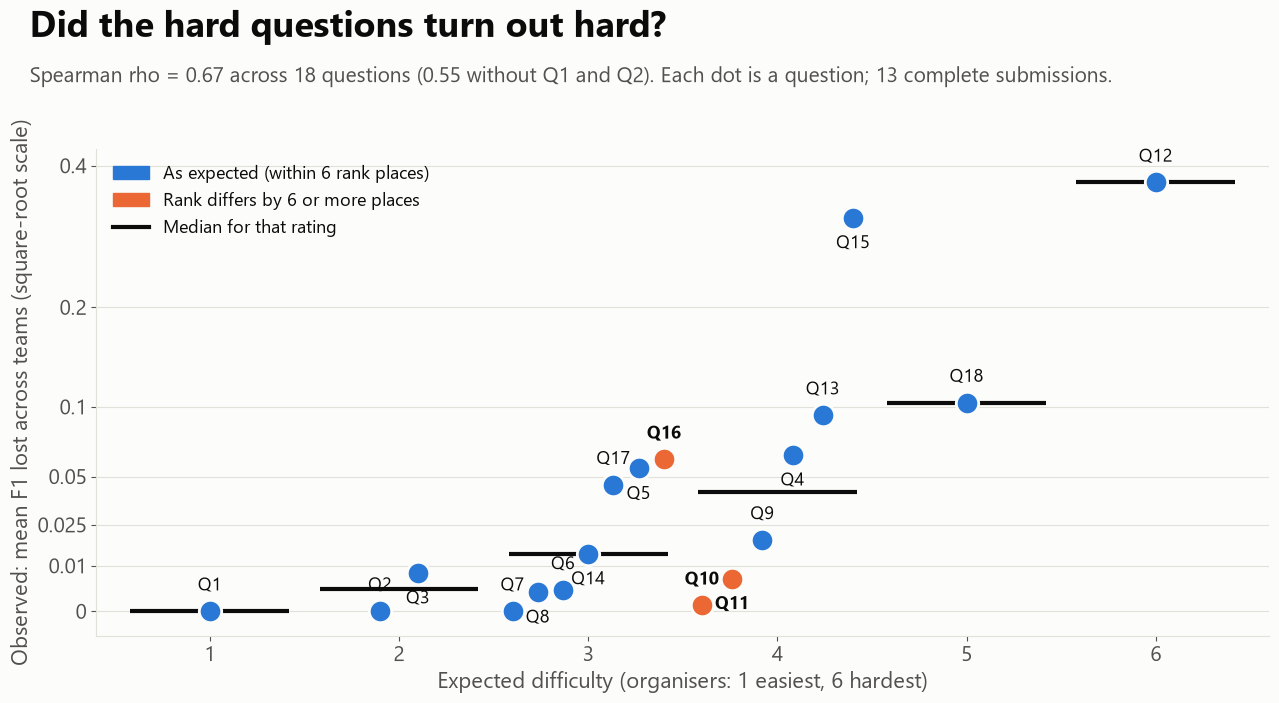

In [11]:
rho_f1 = corr.loc["F1 lost (1 - mean F1)"]
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(left=0.09, right=0.97, top=0.78, bottom=0.13)
for d in sorted(set(DIFFICULTY.values())):
    qs_d = [q for q in QS if DIFFICULTY[q] == d]
    ys = cmp.loc[qs_d, "F1_lost"].sort_values()
    n = len(ys)
    step = min(0.2, 0.8 / max(n - 1, 1))
    for j, (q, yv) in enumerate(ys.items()):
        xv = d + (j - (n - 1) / 2) * step
        flagged = cmp.loc[q, "flag"] != ""
        ax.scatter(xv, yv, s=260, color=ORANGE if flagged else BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, clip_on=False)
        ax.annotate(q, (xv, yv), xytext=(0, 15 if j % 2 == 0 else -22), textcoords="offset points",
                    ha="center", fontsize=13, color=INK, fontweight="bold" if flagged else "normal")
    ax.hlines(ys.median(), d - 0.42, d + 0.42, color=INK, linewidth=3, zorder=2)
ax.set_xticks(range(1, 7))
ax.set_xlim(0.4, 6.6)
ax.set_xlabel("Expected difficulty (organisers: 1 easiest, 6 hardest)")
ax.set_ylabel("Observed: mean F1 lost across teams (square-root scale)")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
OFFSET = 0.003      # keeps zero clear of the axis line on the square-root scale
ax.set_yscale("function", functions=(lambda v: np.sqrt(np.clip(v + OFFSET, 0, None)), lambda v: np.square(v) - OFFSET))
ax.set_ylim(-0.0025, cmp["F1_lost"].max() * 1.15)
ticks = [0, 0.01, 0.025, 0.05, 0.1, 0.2, 0.4]
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:g}" for t in ticks])
ax.legend(handles=[Patch(color=BLUE, label="As expected (within 6 rank places)"),
                   Patch(color=ORANGE, label="Rank differs by 6 or more places"),
                   Line2D([0], [0], color=INK, linewidth=3, label="Median for that rating")],
          loc="upper left", frameon=False, fontsize=13)
headline(fig, "Did the hard questions turn out hard?",
         f"Spearman rho = {rho_f1['Spearman rho (18 questions)']:.2f} across 18 questions "
         f"({rho_f1['Spearman rho (without Q1, Q2)']:.2f} without Q1 and Q2). Each dot is a question; {T} complete submissions.")
path_e = save_fig(fig, "E_expected_vs_observed_difficulty.png")
plt.show()

**Reading Chart E.** The dots rise from left to right, but unevenly. Ratings 1 to 3 sit near zero. The questions rated 4 range from almost no loss (Q10, Q11) to the second largest (Q15). The two outliers, Q12 and Q15, both involve identifying pregnant patients, and `Question_Rationale.md` calls that the hardest part of each. Q15 was rated 4 but turned out to be the second hardest question by a wide margin. The 6-place rule does not flag it, because six questions share rating 4 and their tied rank (5.5) is already near the top.

## 4. Team clustering

**What and why.** We measure how similar two teams are across all 18 questions at once, then cluster them. The distance is **1 minus the mean per-question kappa**, not plain percent agreement over all cells. Pooled percent agreement would be above 98% for almost every pair because most cells are easy True-negatives, and every team would look alike. As a check we repeat the clustering with plain percent agreement and report how much the two trees agree.

We then ask whether the top-scoring teams sit together (a convergent strategy) or spread across clusters (several valid approaches). With only 13 teams this is **low confidence**.

In [12]:
K_MEAN = np.nanmean(KAP, axis=0)       # [team, team]: mean kappa across the 18 questions
A_MEAN = AGR.mean(axis=0)
D_K = 1 - K_MEAN
D_A = 1 - A_MEAN
np.fill_diagonal(D_K, 0)
np.fill_diagonal(D_A, 0)
Z_K = linkage(squareform(D_K, checks=False), method="average")
Z_A = linkage(squareform(D_A, checks=False), method="average")

# how similar are the two trees?
coph_corr = pearsonr(cophenet(Z_K), cophenet(Z_A)).statistic
print(f"Cophenetic correlation between the kappa-based and percent-agreement-based trees: {coph_corr:.2f}")

cl = fcluster(Z_K, t=4, criterion="maxclust")
clusters = pd.DataFrame({"Team": TEAMS, "Rank": range(1, T + 1), "Macro F1": macro.round(4), "Cluster (4)": cl})
display(clusters.sort_values(["Cluster (4)", "Rank"]).set_index("Team"))

top = np.arange(5)
rest = np.arange(5, T)
within_top = D_K[np.ix_(top, top)][np.triu_indices(5, 1)].mean()
between = D_K[np.ix_(top, rest)].mean()
within_rest = D_K[np.ix_(rest, rest)][np.triu_indices(len(rest), 1)].mean()
print(f"Mean distance within the top 5 teams: {within_top:.3f}")
print(f"Mean distance between top 5 and the other 10: {between:.3f}")
print(f"Mean distance within the other 10: {within_rest:.3f}")

Cophenetic correlation between the kappa-based and percent-agreement-based trees: 0.83


,Rank,Macro F1,Cluster (4)
Team,,,
Team 1,1,0.9922,1
Team 2,2,0.9914,1
Team 3,3,0.9898,1
Team 4,4,0.9685,1
Team 5,5,0.9626,1
Team 6,6,0.9497,1
Team 7,7,0.9455,1
Team 8,8,0.9328,1
Team 9,9,0.9243,1


Mean distance within the top 5 teams: 0.026
Mean distance between top 5 and the other 10: 0.090
Mean distance within the other 10: 0.119


**Finding.**
- The top five teams are close to one another (mean distance 0.026). The other eight are further from the top five (0.090) and from each other (0.119). The top ten teams form one cluster, and Teams 11, 12 and 13 each sit in a cluster of their own. The top teams are a **convergent group**, not several different approaches.
- The kappa-based tree and the percent-agreement tree agree reasonably well (cophenetic correlation 0.83), so the grouping does not depend heavily on the distance chosen.
- Confidence: medium. Thirteen teams is a small sample and we have not seen the teams' methods, so "similar answers" is not proof of "similar approach".

### Answer twins

**What and why.** Kappa shows that teams are similar, but not whether they gave *exactly* the same answers. For each question we group teams whose answer columns are identical, row for row. A large group of identical columns that are not perfect means the same mistake was made independently, which is a strong sign of a shared approach (for example, the same ECL).

In [13]:
rows = []
for qi, q in enumerate(QS):
    groups = {}
    for t in range(T):
        groups.setdefault(P[t, qi].tobytes(), []).append(t)
    biggest = max(groups.values(), key=len)
    imperfect = [g for g in groups.values() if len(g) >= 2 and F1[g[0], qi] < 0.999]
    big_wrong = max(imperfect, key=len) if imperfect else []
    rows.append(dict(Question=q, Criterion=SHORT[q], distinct_answer_columns=len(groups),
                     largest_identical_group=len(biggest),
                     largest_identical_group_not_perfect=len(big_wrong),
                     F1_of_that_group=round(float(F1[big_wrong[0], qi]), 4) if big_wrong else np.nan,
                     teams_in_that_group=", ".join(str(g + 1) for g in big_wrong)))
twins = pd.DataFrame(rows).set_index("Question").sort_values("largest_identical_group_not_perfect", ascending=False)
twins.head(8)

,Criterion,distinct_answer_columns,largest_identical_group,largest_identical_group_not_perfect,F1_of_that_group,teams_in_that_group
Question,,,,,,
Q5,Osteoarthritis in 2024,6,8,8,0.9574,"4, 5, 7, 8, 9, 10, 11, 12"
Q4,Hyperthyroidism (clinical note),6,7,7,0.9433,"4, 5, 8, 9, 10, 11, 12"
Q16,Non-Streptococcal bacterial joint infection,9,5,5,0.9883,"4, 7, 8, 9, 12"
Q13,OA/RA + oral NSAID + eGFR < 60,9,5,5,0.9444,"5, 8, 9, 10, 11"
Q14,"Open wound, upper limb (not fingers/thumb)",8,5,2,0.9708,"9, 11"
Q18,Mineral supplement (not Na/K/Cl),12,2,2,0.8144,"8, 9"
Q2,BMI 30+ and chol/HDL > 5,3,11,0,NaN,
Q1,Female,1,13,0,NaN,


**Finding.** On Q5, eight teams (4, 5, 7, 8, 9, 10, 11 and 12) gave exactly the same answer on all 279,912 rows, and all scored F1 0.9574. On Q4, seven teams (4, 5, 8, 9, 10, 11 and 12) did the same, all scoring 0.9433. Identical wrong columns almost certainly mean the same rule or the same query. Confidence: high that the answers are identical; medium that they share a method.

### Chart C: how similar were the teams' answers?

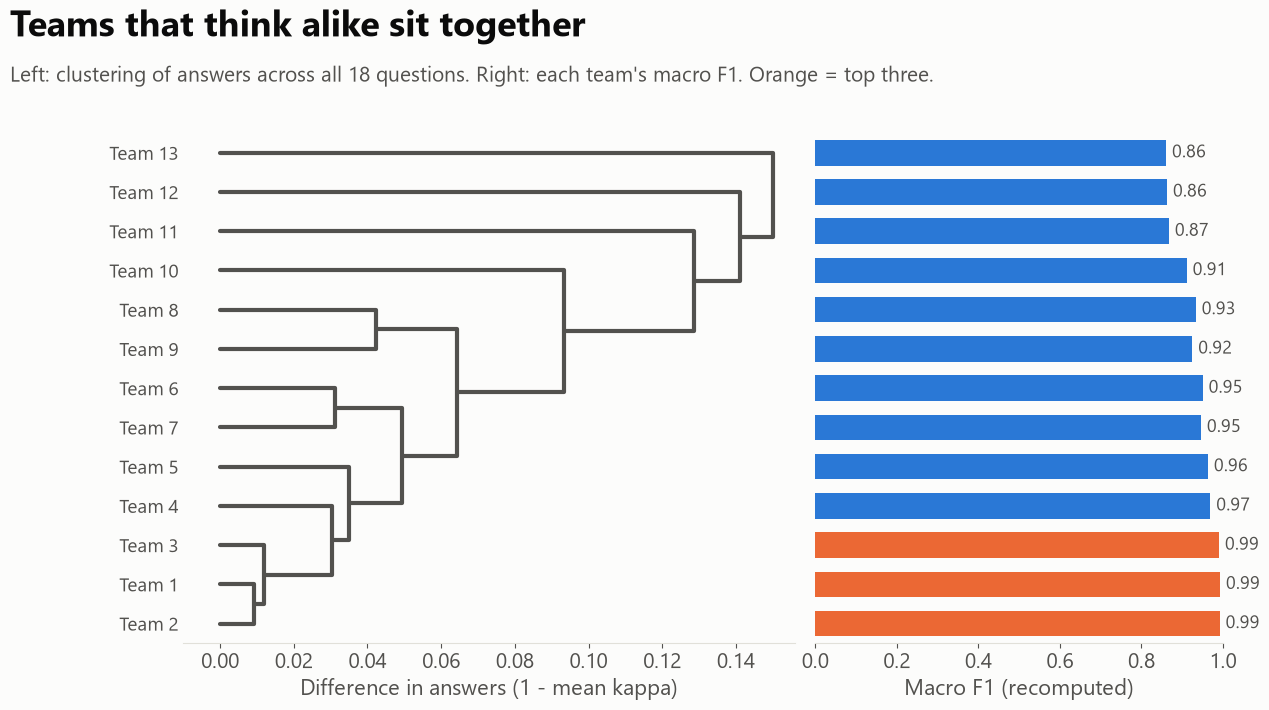

In [14]:
dn = dendrogram(Z_K, no_plot=True)
leaves = dn["leaves"]
ypos = {team: 5 + 10 * i for i, team in enumerate(leaves)}

fig = plt.figure(figsize=SLIDE)
gs = fig.add_gridspec(1, 2, width_ratios=[3.0, 2.0], wspace=0.04, left=0.17, right=0.95, top=0.80, bottom=0.12)
ax = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1], sharey=ax)
for ic, dc in zip(dn["icoord"], dn["dcoord"]):
    ax.plot(dc, ic, color=INK2, linewidth=3, solid_capstyle="round")
ax.set_yticks([ypos[t] for t in leaves])
ax.set_yticklabels([label(t) for t in leaves], fontsize=14)
ax.set_ylim(10 * T, 0)
ax.set_xlim(-0.01, max(dn["dcoord"][-1]) * 1.04)
ax.set_xlabel("Difference in answers (1 - mean kappa)")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
bar_colors = [ORANGE if t < 3 else BLUE for t in leaves]
ax2.barh([ypos[t] for t in leaves], [macro[t] for t in leaves], height=6.5, color=bar_colors)
ax2.set_xlim(0, 1.0)
for t in leaves:
    ax2.text(macro[t] + 0.015, ypos[t], f"{macro[t]:.2f}", va="center", fontsize=13, color=INK2)
ax2.set_xlabel("Macro F1 (recomputed)")
ax2.tick_params(axis="y", left=False, labelleft=False)
ax2.spines["left"].set_visible(False)
headline(fig, "Teams that think alike sit together",
         "Left: clustering of answers across all 18 questions. Right: each team's macro F1. Orange = top three.")
path_c = save_fig(fig, "C_team_clustering.png")
plt.show()

## 5. Row-level contested cases

**What and why.** For every patient and question we count how many of the 13 analysed teams said True. That separates two kinds of contested row:

- **Shared misconception**: at least two thirds of the teams (9 of 13) gave the same answer and it was wrong.
- **Genuine split**: between one third and two thirds of the teams (5 to 8 of 13) said True and the row is not a shared misconception. These are boundary cases where the teams could not agree.

**Who votes.** All 13 analysed teams vote. Teams 14 and 15 are excluded because their columns are all False or close to random, which would create apparent "majorities" that only reflect those columns. As a robustness check the table below repeats the counts with the top 10 teams only.

To make this useful for a SNOMED CT audience, rows are grouped by the **concepts** they carry (the clinical note concept and the medicine concepts) rather than shown one patient at a time. For each concept the tables show how many flagged rows carry it, what share of that concept's rows were flagged, and how often ground truth says True among them. Concepts are ranked by `driver_score` = flagged rows x share flagged, which favours concepts that account for many contested rows *and* are consistently contested.

Confidence: HIGH = 200 or more rows, MEDIUM = 30 to 199, LOW = under 30. Remember that a concept can appear in a contested row only because it sits beside the concept that really causes the problem (for example a clinical note beside a medicine). The `share_flagged` column helps to tell the two apart.

In [15]:
# Every analysed team votes. The sensitivity check repeats the same rule with the top TOP_N_SENSITIVITY teams only.
def vote_masks(PV):
    nv = PV.shape[0]
    n_t = PV.sum(axis=0).astype(np.int16)
    n_w = np.where(Y, nv - n_t, n_t)
    mis_cut = int(np.ceil(MISCONCEPTION_SHARE * nv))
    lo, hi = int(np.ceil(SPLIT_SHARE[0] * nv)), int(np.floor(SPLIT_SHARE[1] * nv))
    mis = n_w >= mis_cut
    spl = (n_t >= lo) & (n_t <= hi) & ~mis
    return n_t, mis, spl, (mis_cut, lo, hi)


n_true, MIS, SPL, (mis_cut, lo, hi) = vote_masks(P)
_, MIS_top, SPL_top, _ = vote_masks(P[:TOP_N_SENSITIVITY])
print(f"Voting teams: all {T} analysed teams.")
print(f"Shared misconception: at least {mis_cut} of {T} teams give the same wrong answer.")
print(f"Genuine split: between {lo} and {hi} of {T} teams say True, and not a misconception.")

row_counts = pd.DataFrame({
    "Criterion": [SHORT[q] for q in QS],
    f"misconception_rows (all {T})": MIS.sum(axis=1),
    f"split_rows (all {T})": SPL.sum(axis=1),
    f"misconception_rows (top {TOP_N_SENSITIVITY})": MIS_top.sum(axis=1),
    f"split_rows (top {TOP_N_SENSITIVITY})": SPL_top.sum(axis=1),
}, index=QS)
row_counts.loc[contest.index]

Voting teams: all 13 analysed teams.
Shared misconception: at least 9 of 13 teams give the same wrong answer.
Genuine split: between 5 and 8 of 13 teams say True, and not a misconception.


,Criterion,misconception_rows (all 13),split_rows (all 13),misconception_rows (top 10),split_rows (top 10)
Question,,,,,
Q12,Pregnant + teratogenic medicine,7,198,3,198
Q15,Pregnant + fasting glucose >= 5.1,62,257,23,248
Q18,Mineral supplement (not Na/K/Cl),337,3770,337,172
Q16,Non-Streptococcal bacterial joint infection,34,4,24,10
Q13,OA/RA + oral NSAID + eGFR < 60,172,32,198,3
Q17,Oral iron supplement,0,0,0,23
Q4,Hyperthyroidism (clinical note),1301,0,30,1271
Q5,Osteoarthritis in 2024,340,0,340,0
Q9,More than one paracetamol product,0,0,0,0


In [16]:
# Patient context: only the columns needed. Identity columns (names, addresses) are never loaded.
KEEP = {ID_COL, "EncounterDate", "DateOfBirth", "Sex", "Clinical_Note_Code", "Clinical_Note_Display",
        "Medicine_1_Code", "Medicine_1_Display", "Medicine_2_Code", "Medicine_2_Display",
        "Medicine_3_Code", "Medicine_3_Display"}


def wanted(c):
    return c in KEEP or c.startswith("MBAP - eGFR") or c.startswith("MBAP - Glucose (fasting)")


tr = pd.read_csv(TRAINING_CSV, usecols=wanted, dtype=str)
assert np.array_equal(tr[ID_COL].astype(int).to_numpy(), sol_ids), "TrainingDataSet is not in the same row order as the solution"
tr["EncounterDate"] = pd.to_datetime(tr["EncounterDate"])
tr["DateOfBirth"] = pd.to_datetime(tr["DateOfBirth"])
tr["age"] = ((tr["EncounterDate"] - tr["DateOfBirth"]).dt.days / 365.25)
egfr_col = [c for c in tr.columns if c.startswith("MBAP - eGFR")][0]
glu_col = [c for c in tr.columns if c.startswith("MBAP - Glucose (fasting)")][0]
tr["eGFR"] = pd.to_numeric(tr[egfr_col], errors="coerce")
tr["fasting_glucose"] = pd.to_numeric(tr[glu_col], errors="coerce")

DISPLAY = {}
SLOTS = [("clinical note", "Clinical_Note_Code", "Clinical_Note_Display"),
         ("medicine", "Medicine_1_Code", "Medicine_1_Display"),
         ("medicine", "Medicine_2_Code", "Medicine_2_Display"),
         ("medicine", "Medicine_3_Code", "Medicine_3_Display")]
for _, cc, dc in SLOTS:
    sub = tr[[cc, dc]].dropna().drop_duplicates(cc)
    DISPLAY.update(dict(zip(sub[cc], sub[dc])))

# total rows carrying each (kind, concept)
TOTALS = {}
for kind, cc, _ in SLOTS:
    vc = tr[cc].dropna().value_counts()
    for code, n in vc.items():
        TOTALS[(kind, code)] = TOTALS.get((kind, code), 0) + int(n)


def confidence(n):
    return "HIGH" if n >= 200 else ("MEDIUM" if n >= 30 else "LOW")


def concept_table(mask, qi):
    """Concepts carried by the flagged rows of question qi, ranked by driver_score."""
    parts = []
    m = np.asarray(mask)
    idx = np.flatnonzero(m)
    if idx.size == 0:
        return pd.DataFrame()
    truth = Y[qi][idx]
    votes = n_true[qi][idx]
    for kind, cc, _ in SLOTS:
        codes = tr[cc].to_numpy()[idx]
        d = pd.DataFrame({"code": codes, "truth": truth, "votes": votes, "ep": sol_ids[idx]}).dropna(subset=["code"])
        g = d.groupby("code").agg(rows_flagged=("truth", "size"), truth_true_share=("truth", "mean"),
                                  mean_teams_true=("votes", "mean"), example_episode=("ep", "first"))
        g["kind"] = kind
        parts.append(g.reset_index())
    out = pd.concat(parts)
    out = out.groupby(["kind", "code"], as_index=False).agg(
        rows_flagged=("rows_flagged", "sum"), truth_true_share=("truth_true_share", "mean"),
        mean_teams_true=("mean_teams_true", "mean"), example_episode=("example_episode", "first"))
    out["rows_total"] = [TOTALS[(k, c)] for k, c in zip(out["kind"], out["code"])]
    out["share_flagged"] = out["rows_flagged"] / out["rows_total"]
    out["driver_score"] = out["rows_flagged"] * out["share_flagged"]
    out["display"] = out["code"].map(DISPLAY)
    out["confidence"] = out["rows_flagged"].map(confidence)
    cols = ["kind", "code", "display", "rows_flagged", "rows_total", "share_flagged",
            "truth_true_share", "mean_teams_true", "driver_score", "confidence", "example_episode"]
    return out[cols].sort_values("driver_score", ascending=False)


FLAGGED = {"misconception": MIS, "split": SPL}
all_tables = []
for qi, q in enumerate(QS):
    for kind, mask in FLAGGED.items():
        t = concept_table(mask[qi], qi)
        if len(t):
            t.insert(0, "question", q)
            t.insert(1, "type", kind)
            all_tables.append(t.head(10))
examples = pd.concat(all_tables, ignore_index=True)
examples.round(3).to_csv(os.path.join(OUT, "row_level_examples.csv"), index=False)
print(f"Saved the top 10 concepts per question and type to {OUT}/row_level_examples.csv ({len(examples)} rows).")

Saved the top 10 concepts per question and type to outputs/row_level_examples.csv (134 rows).


### Shared misconceptions, most contested questions first
These are rows where at least two thirds of teams agreed with each other and were wrong. `truth_true_share` is the share of those rows where ground truth is True.

In [17]:
MIN_FLAGGED = 20      # only list a question when at least this many rows are flagged
mis_q = [q for q in contest.index if MIS[QS.index(q)].sum() >= MIN_FLAGGED]
spl_q = [q for q in contest.index if SPL[QS.index(q)].sum() >= MIN_FLAGGED]
print("Questions listed (most contested first). Misconceptions:", mis_q, "| splits:", spl_q)
for q in mis_q:
    qi = QS.index(q)
    t = concept_table(MIS[qi], qi).head(5)
    if len(t):
        print(f"\n{q}  {QTEXT[q]}\n   shared-misconception rows: {int(MIS[qi].sum()):,}")
        display(t.drop(columns=["code"]).round(3).reset_index(drop=True))

Questions listed (most contested first). Misconceptions: ['Q15', 'Q18', 'Q16', 'Q13', 'Q4', 'Q5'] | splits: ['Q12', 'Q15', 'Q18', 'Q13', 'Q14']

Q15  Pregnant patients with a fasting glucose of 5.1 mmol/L or greater.
   shared-misconception rows: 62


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Iron deficiency anaemia in mother complicating childbirth,25,182,0.137,1.0,4.0,3.434,LOW,99393
1,clinical note,Severe pre-eclampsia - delivered,8,43,0.186,1.0,4.0,1.488,LOW,98306
2,clinical note,Amniotic fluid cell content OK,2,3,0.667,1.0,3.0,1.333,LOW,121173
3,clinical note,Seven previous induced terminations of pregnancy,2,3,0.667,1.0,1.0,1.333,LOW,41870
4,clinical note,Helical ulceration of umbilical cord,1,1,1.000,1.0,3.0,1.000,LOW,196128



Q18  Patients taking mineral supplement excluding the electrolytes sodium, potassium or chloride.
   shared-misconception rows: 337


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,medicine,Miconazole nitrate 2.5 microgram/mg and zinc oxide 150 microgram/m...,98,98,1.0,1.0,2.0,98.0,MEDIUM,17302
1,medicine,Daktozin ointment,45,45,1.0,1.0,2.0,45.0,MEDIUM,190537
2,medicine,Resolve Nappy Rash ointment,39,39,1.0,1.0,2.0,39.0,MEDIUM,187562
3,medicine,Amolin Baby cream (Old Formulation 2010),29,29,1.0,1.0,2.0,29.0,LOW,186537
4,medicine,Soov Prickly Heat powder,27,27,1.0,1.0,2.0,27.0,LOW,190912



Q16  Patients with a non-Streptococcal bacterial joint infection.
   shared-misconception rows: 34


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Bacterial spondyloarthritis,10,10,1.000,1.0,4.0,10.000,LOW,103974
1,clinical note,Postinfective arthropathy following infection caused by Mycobacterium,8,10,0.800,1.0,3.0,6.400,LOW,5379
2,clinical note,Hydrarthrosis of yaws,5,5,1.000,1.0,4.0,5.000,LOW,38872
3,clinical note,Reactive arthropathy following infection caused by Mycobacterium,6,13,0.462,1.0,3.0,2.769,LOW,23199
4,clinical note,Infection of intervertebral disc caused by bacterium,2,2,1.000,1.0,4.0,2.000,LOW,105661


... (2 outputs left out)


Q4  Patients with hyperthyroidism according to their clinical note.
   shared-misconception rows: 1,301


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Familial dysalbuminaemic hyperthyroxinaemia,637,637,1.000,0.0,9.0,637.000,HIGH,1404
1,clinical note,Dysprealbuminaemic euthyroidal hyperthyroxinaemia,634,634,1.000,0.0,9.0,634.000,HIGH,380
2,clinical note,Thyrotoxicosis due to pituitary thyroid hormone resistance,28,34,0.824,1.0,2.0,23.059,LOW,61536
3,medicine,Thiamazole 15 mg oral tablet,86,988,0.087,0.0,9.0,7.486,MEDIUM,1711
4,medicine,Carbimazole 5 mg oral tablet,79,1005,0.079,0.0,9.0,6.210,MEDIUM,10114



Q5  Patients with osteoarthritis in 2024.
   shared-misconception rows: 340

,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Bilateral gouty tophus of elbows,47,272,0.173,0.0,9.0,8.121,MEDIUM,135225
1,clinical note,Chondrocalcinosis of right hip,6,9,0.667,0.0,10.0,4.000,LOW,137974
2,clinical note,Chronic tophaceous gout of knee due to drug,8,19,0.421,0.0,9.0,3.368,LOW,145064
3,clinical note,Chondrocalcinosis due to dicalcium phosphate crystals,7,19,0.368,0.0,11.0,2.579,LOW,151258
4,clinical note,Chronic tophaceous gout due to drug,6,16,0.375,0.0,9.0,2.250,LOW,134208


### Genuine splits, most contested questions first
These are rows where teams were roughly evenly divided.

In [18]:
for q in spl_q:
    qi = QS.index(q)
    t = concept_table(SPL[qi], qi).head(5)
    if len(t):
        print(f"\n{q}  {QTEXT[q]}\n   split rows: {int(SPL[qi].sum()):,}")
        display(t.drop(columns=["code"]).round(3).reset_index(drop=True))


Q12  Pregnant patients prescribed a teratogenic medicine.
   split rows: 198


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Transient hypertension of pregnancy - not delivered,33,45,0.733,0.303,5.818,24.200,MEDIUM,4438
1,clinical note,Toxaemia of pregnancy,9,15,0.600,0.000,5.889,5.400,LOW,446
2,clinical note,Pre-existing hypertension in obstetric context,5,6,0.833,0.600,6.400,4.167,LOW,44011
3,clinical note,Severe pre-eclampsia - not delivered,12,38,0.316,1.000,6.000,3.789,LOW,98459
4,clinical note,Chronic hypertension complicating AND/OR reason for care during pr...,7,13,0.538,0.000,6.000,3.769,LOW,5964



Q15  Pregnant patients with a fasting glucose of 5.1 mmol/L or greater.
   split rows: 257


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Iron deficiency anaemia of pregnancy,64,340,0.188,0.000,6.312,12.047,MEDIUM,768
1,clinical note,Maternal syphilis during pregnancy - baby not yet delivered,29,110,0.264,0.207,5.414,7.645,LOW,15176
2,clinical note,Transient hypertension of pregnancy - not delivered,16,45,0.356,0.312,5.938,5.689,LOW,7346
3,clinical note,Chronic hypertension in obstetric context,5,9,0.556,0.400,6.200,2.778,LOW,9509
4,clinical note,Hypertensive renal disease in obstetric context,3,4,0.750,0.667,7.000,2.250,LOW,43767



Q18  Patients taking mineral supplement excluding the electrolytes sodium, potassium or chloride.
   split rows: 3,770


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,medicine,Ferrous fumarate 305 mg and folic acid 350 microgram oral capsule,493,512,0.963,1.0,8.0,474.705,HIGH,243
1,medicine,Ferric ammonium citrate 16 mg/mL and folic acid 100 microgram/mL o...,486,507,0.959,1.0,8.0,465.870,HIGH,1866
2,medicine,Ferrous sulfate 150 mg and folic acid 500 microgram prolonged-rele...,477,499,0.956,1.0,8.0,455.970,HIGH,461
3,medicine,Ferric ammonium citrate 16 mg/mL and folic acid 500 microgram/mL o...,470,489,0.961,1.0,8.0,451.738,HIGH,561
4,medicine,Ferrous fumarate 324 mg and folic acid 1 mg oral tablet,467,498,0.938,1.0,8.0,437.930,HIGH,882



Q13  Patients with osteoarthritis or rheumatoid arthritis taking an oral NSAID, and their eGFR is below 60.
   split rows: 32


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Bilateral gouty tophus of elbows,13,272,0.048,0.0,8.0,0.621,LOW,11577
1,clinical note,Polyarticular acute gout caused by lead,2,11,0.182,0.0,8.0,0.364,LOW,61772
2,clinical note,Chronic tophaceous gout of wrist due to drug,2,16,0.125,0.0,8.0,0.250,LOW,41049
3,clinical note,Chronic tophaceous gout due to drug,2,16,0.125,0.0,8.0,0.250,LOW,134208
4,clinical note,Monoarticular acute gout caused by lead,1,14,0.071,0.0,8.0,0.071,LOW,78235



Q14  Patients with an open wound on an upper limb, excluding the fingers and thumb.
   split rows: 55


,kind,display,rows_flagged,rows_total,share_flagged,truth_true_share,mean_teams_true,driver_score,confidence,example_episode
0,clinical note,Laceration of fascia of intrinsic muscle of finger,14,16,0.875,1.0,8.0,12.250,LOW,25820
1,clinical note,Laceration of intrinsic muscle of finger,14,19,0.737,1.0,8.0,10.316,LOW,16188
2,clinical note,Open fracture thumb metacarpal head,9,16,0.562,1.0,8.0,5.062,LOW,241981
3,clinical note,Open fracture thumb metacarpal neck,7,20,0.350,1.0,8.0,2.450,LOW,238641
4,clinical note,Open fracture of thumb metacarpal,4,13,0.308,1.0,8.0,1.231,LOW,233513


**Finding.** With all 13 analysed teams voting:
- *Shared misconceptions* (at least 9 of 13 wrong together) are concentrated in **Q4** (1,301 rows, led by the two hyperthyroxinaemia notes), **Q5** (340 rows, all in 2024, ground truth False, with gout and chondrocalcinosis-type notes among the most common), **Q18** (337 rows, led by skin products containing zinc, where only 2 of 13 teams on average said True and ground truth is True), **Q13** (172 rows spread over many concepts) and small numbers on Q15 (62) and Q16 (34).
- *Genuine splits* (5 to 8 of 13 teams saying True) are concentrated in **Q18** (3,770 rows, mostly iron-and-folic-acid products that five teams miss), **Q15** (257) and **Q12** (198), the pregnancy questions. Q14 has 55 and Q13 has 32.
- Q17, Q9, Q3, Q11, Q6, Q8, Q7, Q2 and Q1 have no flagged rows of either kind. Q10 has 10.
- **The voting pool matters for two questions.** On Q4, nine of 13 teams (69%) said True on the hyperthyroxinaemia notes, just over the two-thirds line, so the same rows are a "shared misconception" with 13 voters but a "genuine split" (1,271 rows) with the top 10. On Q18, split rows are 3,770 with 13 voters but 172 with the top 10, because most of the teams that miss the iron-and-folic-acid products are ranked 8 to 13.
- Confidence: high for the Q4 and Q18 counts (hundreds of rows per concept). Low for the Q15, Q16 and Q13 concept lists, where each concept has fewer than 30 flagged rows and may only sit next to the real cause. Those lists should not go on a slide.

## 6. Shortlist for the talk

**What and why.** The steps above point to four findings that a SNOMED CT audience will recognise from their own work. Each gets its own chart. For each one the evidence is computed below; the plain-language reading follows the chart.

Shared helpers: a strip chart that shows, for chosen groups of patients, how often each team's answer differed from ground truth. Groups are built from the clinical note and medicine names in `TrainingDataSet.csv`. Keyword groups are approximate and are labelled as such.

In [19]:
note = tr["Clinical_Note_Display"].fillna("")
med_text = tr[["Medicine_1_Display", "Medicine_2_Display", "Medicine_3_Display"]].fillna("").agg(" | ".join, axis=1).str.lower()
year = tr["EncounterDate"].dt.year.to_numpy()


def wrap(text, width):
    out, line = [], ""
    for word in text.split():
        if line and len(line) + 1 + len(word) > width:
            out.append(line)
            line = word
        else:
            line = (line + " " + word).strip()
    out.append(line)
    return "\n".join(out)


def truth_label(share):
    if share >= 0.99:
        return "truth: True"
    if share <= 0.01:
        return "truth: False"
    return f"truth: {share:.0%} True"


def group_strip(qi, groups, title, subtitle, fname, left=0.17, wrap_at=20, footnote=None):
    """Teams x patient groups: share of rows where the team's answer differs from ground truth."""
    names = list(groups)
    masks = [np.asarray(groups[n]) for n in names]
    W = np.array([[float((P[t, qi][m] != Y[qi][m]).mean()) for m in masks] for t in range(T)])
    fig, ax = plt.subplots(figsize=SLIDE)
    fig.subplots_adjust(left=left, right=0.97, top=0.66, bottom=0.07)
    cmap = LinearSegmentedColormap.from_list("loss", SEQ_BLUE)
    ax.imshow(W, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(T))
    ax.set_yticklabels([label(k) for k in range(T)], fontsize=14)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([f"{wrap(n, wrap_at)}\n{int(m.sum()):,} rows\n{truth_label(Y[qi][m].mean())}" for n, m in zip(names, masks)],
                       fontsize=12.5, color=INK)
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(-.5, len(names), 1), minor=True)
    ax.set_yticks(np.arange(-.5, T, 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=3)
    ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    for r in range(T):
        for c in range(len(names)):
            v = W[r, c]
            ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=13,
                    color="white" if v > 0.55 else (INK if v > 0.04 else MUTED))
    headline(fig, title, subtitle)
    if footnote:
        fig.text(0.04, 0.012, footnote, fontsize=12, color=INK2, va="bottom")
    save_fig(fig, fname)
    plt.show()
    return pd.DataFrame(W, index=TEAMS, columns=names)


T14_NOTE = None

### Finding 1 (Q4): "hyperthyroxinaemia" is not "hyperthyroidism"... or is it?

**What and why.** Q4 asks for hyperthyroidism "according to the clinical note". Two clinical note concepts are named as hyperthyroxinaemia: *Familial dysalbuminaemic hyperthyroxinaemia* and *Dysprealbuminaemic euthyroidal hyperthyroxinaemia*. The chart shows how each team answered on these rows, next to two other "looks like hyperthyroidism" groups.

1,271 rows carry a hyperthyroxinaemia note. Ground truth is True for 0 of them.
9 of 13 teams answered True on most of those rows: teams [4, 5, 7, 8, 9, 10, 11, 12, 13].


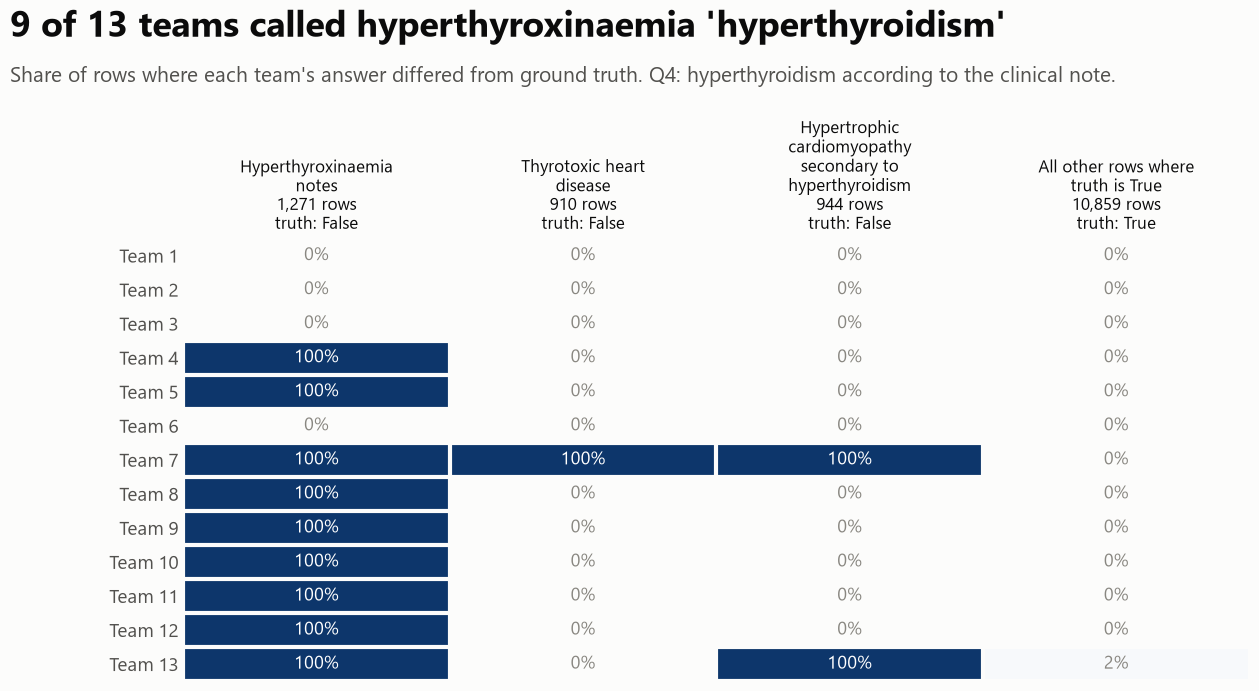

,Hyperthyroxinaemia notes,Thyrotoxic heart disease,Hypertrophic cardiomyopathy secondary to hyperthyroidism,All other rows where truth is True
Team 1,0.0,0.0,0.0,0.003
Team 2,0.0,0.0,0.0,0.003
Team 3,0.0,0.0,0.0,0.003
Team 4,1.0,0.0,0.0,0.003
Team 5,1.0,0.0,0.0,0.003
Team 6,0.0,0.0,0.0,0.000
Team 7,1.0,1.0,1.0,0.000
Team 8,1.0,0.0,0.0,0.003
Team 9,1.0,0.0,0.0,0.003
Team 10,1.0,0.0,0.0,0.003


In [20]:
q4 = QS.index("Q4")
g_q4 = {
    "Hyperthyroxinaemia notes": note.str.contains("hyperthyroxinaemia", case=False).to_numpy(),
    "Thyrotoxic heart disease": note.str.contains("Thyrotoxic heart", case=False).to_numpy(),
    "Hypertrophic cardiomyopathy secondary to hyperthyroidism": note.str.contains("Hypertrophic cardiomyopathy secondary to hyperthyroidism", case=False).to_numpy(),
    "All other rows where truth is True": Y[q4] & ~note.str.contains("hyperthyroxinaemia|Thyrotoxic heart|Hypertrophic cardiomyopathy secondary", case=False).to_numpy(),
}
n_hx = int(g_q4["Hyperthyroxinaemia notes"].sum())
# measure the share of teams that answered True on these rows (truth is False for all of them)
share_true_hx = P[:, q4][:, g_q4["Hyperthyroxinaemia notes"]].mean(axis=1)
n_teams_hx = int((share_true_hx > 0.5).sum())
print(f"{n_hx:,} rows carry a hyperthyroxinaemia note. Ground truth is True for {int(Y[q4][g_q4['Hyperthyroxinaemia notes']].sum())} of them.")
print(f"{n_teams_hx} of {T} teams answered True on most of those rows: teams {[int(k) + 1 for k in np.flatnonzero(share_true_hx > 0.5)]}.")
d1 = group_strip(q4, g_q4,
                 f"{n_teams_hx} of {T} teams called hyperthyroxinaemia 'hyperthyroidism'",
                 "Share of rows where each team's answer differed from ground truth. Q4: hyperthyroidism according to the clinical note.",
                 "D1_Q4_hyperthyroxinaemia.png", wrap_at=22, footnote=T14_NOTE)
d1.round(3)

**Result.** 1,271 rows carry a hyperthyroxinaemia note. Ground truth is False for every one. Nine of 13 teams (4, 5 and 7 to 13) answered True on all of them. Teams 1, 2, 3 and 6 answered False. Team 7 went further and also answered True on the thyrotoxic heart disease rows, and Teams 7 and 13 did so on the hypertrophic cardiomyopathy rows.

**Why this matters for a SNOMED CT audience.** On Ontoserver (default edition at the time of checking), `34486009 |Hyperthyroidism|` subsumes `237547004 |Familial dysalbuminaemic hyperthyroxinaemia|`. A plain "descendants of hyperthyroidism" query therefore returns these concepts, while the competition's ground truth treats them as not hyperthyroidism. We do not pick a side. The ground truth defines the score, but this is a real tension between what the hierarchy says and how a clinician reads a euthyroid state. We checked that subsumption for the first concept only, in one edition, and did not check each of the six editions.

The organisers expected trouble of this kind. `Question_Rationale.md` says that "not every coded diagnosis is formally hyperthyroidism" and that a precise answer "needs careful research". It also names a different problem on the same question, the 2022 move of *Thyrotoxicosis* out from under *Hyperthyroidism*. The question was rated 4 and was fifth hardest by outcome, so the rating held up.

**Confidence.** High on the counts. Medium on the interpretation, because we have not seen the teams' queries. The seven identical answer columns on Q4 (see "Answer twins") support the idea of one shared rule.

### Finding 2 (Q15): right by the answer key's rule, wrong in the clinic

**What and why.** The data spans six SNOMED CT-AU editions, and the answer key answers each encounter with the edition current on its date. For pregnancy it used `<< 118185001 |Finding related to pregnancy|`. If a concept moved in or out of that grouping between editions, the key's answer for the same note text changes with the year, whether or not the clinical meaning changed. We test that on Q15 (pregnant, fasting glucose of 5.1 or more). Restricting to rows with glucose of 5.1 or more removes the glucose condition, so any change in the key across years for one concept reflects the pregnancy definition.

We first count concepts whose answer-key value flips between years, then look at each team's answers on the clearest case, *Iron deficiency anaemia of pregnancy* (199248002).


In [ ]:
q15 = QS.index("Q15")
gl_ok = (tr["fasting_glucose"] >= 5.1).to_numpy()
d = pd.DataFrame({"note": note.to_numpy(), "year": year, "truth": Y[q15]})[gl_ok]
cell = d.groupby(["note", "year"]).agg(n=("truth", "size"), truth=("truth", "mean")).reset_index()
cell = cell[cell["n"] >= 3]
by_note = cell.groupby("note").agg(years=("year", "nunique"), max_truth=("truth", "max"), min_truth=("truth", "min"))
flip = by_note[(by_note["years"] >= 2) & (by_note["max_truth"] >= 0.9) & (by_note["min_truth"] <= 0.1)]
flip_mask = gl_ok & note.isin(flip.index).to_numpy()
print(f"{len(flip)} clinical note concepts have ground truth that is True in some years and False in others (Q15, glucose >= 5.1, at least 3 rows per year).")
print(f"They cover {int(flip_mask.sum()):,} rows, of which ground truth is True for {int(Y[q15][flip_mask].sum()):,}.")
acc = pd.Series([float((P[t, q15][flip_mask] == Y[q15][flip_mask]).mean()) for t in range(T)], index=TEAMS, name="share correct on these rows")
print("Share of those rows each team answered correctly:")
display(acc.round(3).to_frame().T)
below = (tr["fasting_glucose"] < 5.1).to_numpy()
print(f"Rows with fasting glucose below 5.1: {int(below.sum()):,}. Rows where any of the top 10 teams answered True: {int(P[:10, q15][:, below].any(axis=0).sum())}.")
print("So the 5.1 threshold itself is applied consistently; the disagreement is about which notes count as pregnant.")

# Per-team answers by year on the clearest case
ida = "Iron deficiency anaemia of pregnancy"
ida_mask = (note == ida).to_numpy() & gl_ok
ida_years = sorted(y for y in set(year[ida_mask]) if (year[ida_mask] == y).sum() >= 5)
ida_tab = pd.DataFrame({y: [float(P[t, q15][ida_mask & (year == y)].mean()) for t in range(T)] for y in ida_years}, index=TEAMS)
ida_tab.loc["Answer key"] = [float(Y[q15][ida_mask & (year == y)].mean()) for y in ida_years]
print(f"{ida}: {int(ida_mask.sum())} rows. Share answered True, by encounter year:")
display(ida_tab.round(2))


**Result.** Seven clinical note concepts have an answer-key value that is False in earlier years and True later, on 228 rows. The clearest is *Iron deficiency anaemia of pregnancy* (95 rows), where the key says False to 2024 and True from 2025. On that concept the teams took four distinct approaches, with identical row-level answers inside each group:
- Five teams (1, 2, 4, 5 and 10) match the answer key exactly.
- Team 3 makes the same switch one year early, in 2024.
- Six teams (6, 7, 8, 9, 12 and 13) answer True in every year.
- Team 11 answers False in every year.

The fasting glucose threshold is not the cause: no top 10 team answered True below 5.1.

**Why this matters for a SNOMED CT audience.** The change is in the terminology, not the clinic. Checked on Ontoserver (SNOMED CT-AU), the 20240131 edition gives 199248002 only haematology ancestors (for example *Iron deficiency anaemia*, *Nutritional anaemia*), with no link to pregnancy. The 20250131 edition adds *Maternal disorder during pregnancy* and *Disorder of pregnancy*, which places it under *Finding related to pregnancy*. So the answer key is correct by its own rule, but the rule missed a concept whose name states the pregnancy: the organisers did not include 199248002 for 2021 to 2024, and should have. The six teams that answered True in every year gave the clinically right answer and were scored wrong for those years.

The general point: answering with the edition current at each encounter keeps concepts that were later retired, but it also faithfully reproduces that edition's modelling gaps. Answering with a later edition benefits from corrected modelling but loses retired concepts that history supplements cannot recover (see the history supplement analysis). The six "True in every year" teams are not one strategy, though: their recall on retired obstetric codes ranges widely, so some probably combined editions rather than using the latest alone.

**Effect on scores.** Treating 199248002 as pregnancy in every year changes 64 Q15 rows. On the full dataset, Teams 1 and 3 then finish level on macro F1 (0.98880 and 0.98883) and Team 2 is third (0.98807). Treating all seven concepts that way puts Team 3 first (0.9870, against 0.9856 and 0.9850). The official placings stand: they use the published key and Kaggle's private split.

**Confidence.** High for the four approaches on 199248002 (95 rows, identical answers within each group) and for the hierarchy change (checked directly). Medium for the other six concepts, whose SNOMED CT history we have not checked. We cannot see which edition each team queried. See also `../TerminologyDrift.md`.


In [ ]:
# One line per team on the clearest case. Lines with identical answers are nudged towards 50% so each stays visible.
ida_x = np.arange(len(ida_years))
fig, ax = plt.subplots(figsize=SLIDE)
fig.subplots_adjust(left=0.09, right=0.97, top=0.78, bottom=0.16)
patterns = {}
for t in range(T):
    patterns.setdefault(tuple(ida_tab.iloc[t].round(2)), []).append(t)
for ts in patterns.values():
    for k, t in enumerate(ts):
        s = ida_tab.iloc[t].to_numpy()
        off = (k + 1) * 0.008
        top3 = t < 3
        ax.plot(ida_x, s + off * (1 - 2 * s), color=ORANGE if top3 else BLUE, linewidth=2.6 if top3 else 1.7,
                linestyle="-" if top3 else (0, (5, 3)), zorder=3 if top3 else 2)
ax.plot(ida_x, ida_tab.loc["Answer key"], color=INK, linewidth=4.5, marker="s", markersize=10, zorder=5)
key_row = ida_tab.loc["Answer key"].round(2).to_numpy()
for ts in patterns.values():
    s = ida_tab.iloc[ts[0]].round(2).to_numpy()
    who = f"Team{'s' if len(ts) > 1 else ''} " + ", ".join(str(t + 1) for t in ts)
    if s.min() > 0.5:
        ax.text(0.05, 0.86, f"{who}: True in every year", fontsize=13, color=INK2)
    elif s.max() < 0.5:
        ax.text(len(ida_x) - 2.4, 0.12, f"{who}: never True", fontsize=13, color=INK2)
    elif (s == key_row).all():
        ax.text(0.05, 0.16, f"{who}: follow the answer key", fontsize=13, color=INK2)
    else:
        sw = int(np.argmax(s > 0.5))
        ax.text(max(sw - 2.2, 0.05), 0.55, f"{who}: switches in {ida_years[sw]}", fontsize=13, color=INK2)
ax.set_xticks(ida_x)
ax.set_xticklabels([str(y) for y in ida_years], fontsize=14)
ax.set_yticks([0, 0.5, 1.0])
ax.set_yticklabels(["0%", "50%", "100%"])
ax.set_ylim(-0.06, 1.06)
ax.set_ylabel("Rows answered True")
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
for s_ in ("top", "right"):
    ax.spines[s_].set_visible(False)
handles = [Line2D([], [], color=INK, linewidth=4.5, marker="s", markersize=9),
           Line2D([], [], color=ORANGE, linewidth=2.6),
           Line2D([], [], color=BLUE, linewidth=1.7, linestyle=(0, (5, 3)))]
fig.legend(handles, ["Answer key", "Teams 1-3", f"Teams 4-{T}"], loc="lower center", ncol=3, frameon=False, fontsize=15, bbox_to_anchor=(0.5, 0.0))
headline(fig, "Right by the rule, wrong in the clinic",
         f"Q15, {ida}: {int(ida_mask.sum())} rows with fasting glucose 5.1 or more. One line per team, nudged apart to stay visible.\n"
         "The answer key follows the edition; six teams answered True in every year.")
save_fig(fig, "D2_Q15_edition_drift.png")
plt.show()


### Finding 3 (Q14): "digital" and "finger" in a name are not the same as the finger in the model

**What and why.** Q14 asks for an open wound on an upper limb, excluding the fingers and thumb. Some clinical notes contain the words *digital* or *finger* but, in ground truth, are counted as upper limb rows that are not finger or thumb rows. Other notes about thumb and finger amputation are not. The chart compares each team's answers across these groups.

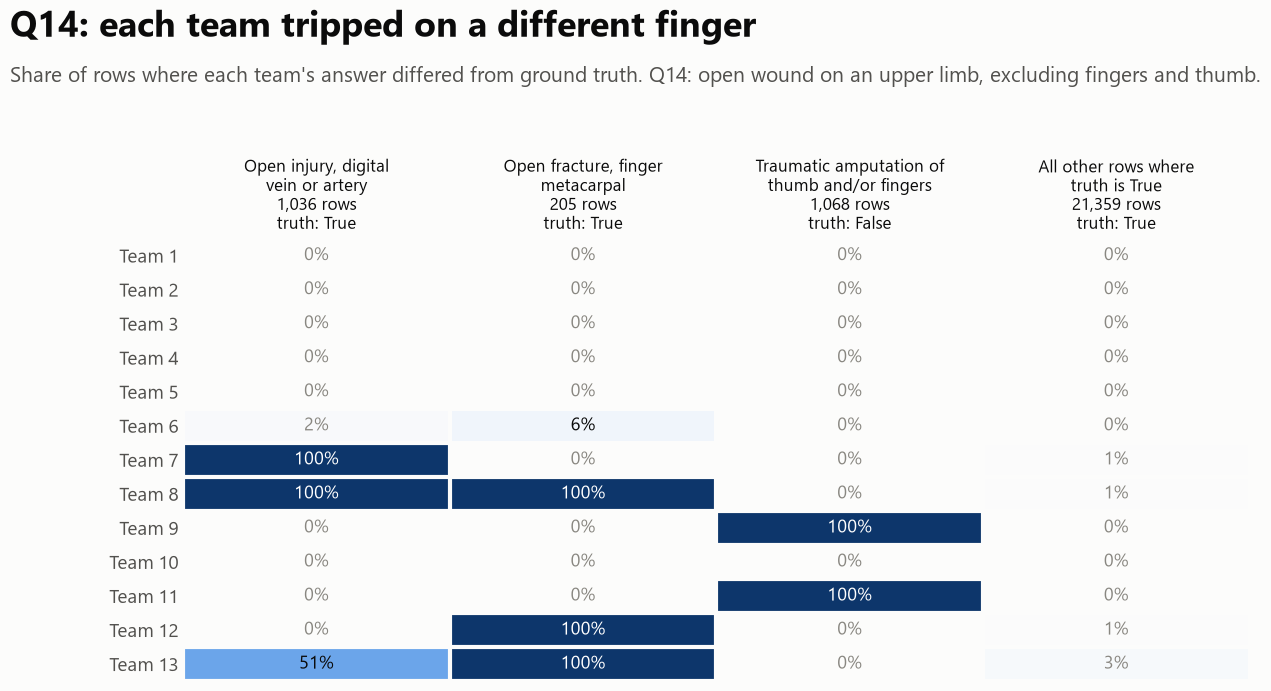

,"Open injury, digital vein or artery","Open fracture, finger metacarpal",Traumatic amputation of thumb and/or fingers,All other rows where truth is True
Team 1,0.000,0.000,0.0,0.000
Team 2,0.000,0.000,0.0,0.000
Team 3,0.000,0.000,0.0,0.000
Team 4,0.000,0.000,0.0,0.000
Team 5,0.000,0.000,0.0,0.000
Team 6,0.023,0.063,0.0,0.004
Team 7,1.000,0.000,0.0,0.008
Team 8,1.000,1.000,0.0,0.008
Team 9,0.000,0.000,1.0,0.000
Team 10,0.000,0.000,0.0,0.000


In [23]:
q14 = QS.index("Q14")
g_q14 = {
    "Open injury, digital vein or artery": note.str.contains(r"^Open injury, digital (?:vein|artery)", case=False).to_numpy(),
    "Open fracture, finger metacarpal": note.str.contains("Open fracture finger metacarpal", case=False).to_numpy(),
    "Traumatic amputation of thumb and/or fingers": note.str.contains("Traumatic amputation of thumb AND/OR fingers", case=False).to_numpy(),
}
g_q14["All other rows where truth is True"] = Y[q14] & ~(g_q14["Open injury, digital vein or artery"] | g_q14["Open fracture, finger metacarpal"])
d3 = group_strip(q14, g_q14,
                 "Q14: each team tripped on a different finger",
                 "Share of rows where each team's answer differed from ground truth. Q14: open wound on an upper limb, excluding fingers and thumb.",
                 "D3_Q14_digital_finger.png", wrap_at=24, footnote=T14_NOTE)
d3.round(3)

**Result.** Teams 1 to 5 and 10 are perfect on every group here. The other teams each slipped differently:
- Teams 7 and 8 answered False on 1,036 *Open injury, digital vein or artery* rows, where ground truth is True. Team 13 did so on about half of them.
- Teams 8, 12 and 13 answered False on 205 *Open fracture, finger metacarpal* rows, where ground truth is True.
- Teams 9 and 11 answered True on 1,068 *Traumatic amputation of thumb and/or fingers* rows, where ground truth is False.

No failure is shared by more than three teams. This contrasts with Q4 and Q5, where seven or eight teams made one identical error.

**Why this matters for a SNOMED CT audience.** The words "digital" and "finger" in a concept name do not map cleanly onto the exclusion of "fingers and thumb". Reading by name goes wrong in both directions: ground truth keeps *finger metacarpal* fractures and digital vessel injuries in, and keeps thumb and finger amputations out. `Question_Rationale.md` describes the intended ECL as finding open wounds in the upper limb and then subtracting the digits, which is a statement about modelled anatomy and not about the words in a term. We have not checked how these concepts are modelled.

**Confidence.** Medium. The groups are found by name and are small (205 to 1,068 rows). The reasons teams slipped are hypotheses. The question was rated 3 and was tenth hardest by outcome.

### Finding 4 (Q18): "mineral supplement" in the question, ingredients in the answer

**What and why.** Q18 asks for patients taking a mineral supplement, excluding sodium, potassium and chloride. Ground truth is True for many products that are not supplements in everyday terms (nappy-rash ointments containing zinc oxide, medicated shampoos, iron-containing phosphate binders). We group the ground-truth-True rows by the words in the medicine names to see which kinds of product each team captured. The groups are **approximate**: they come from keywords, not from the terminology.

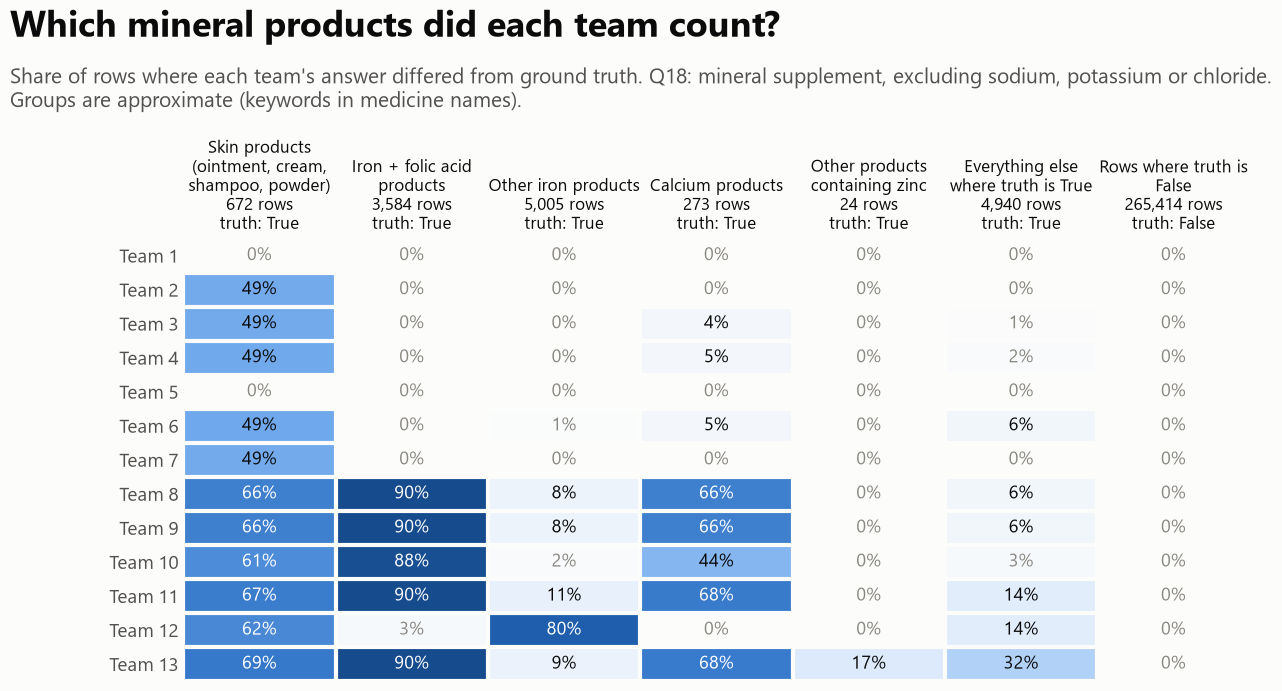

,"Skin products (ointment, cream, shampoo, powder)",Iron + folic acid products,Other iron products,Calcium products,Other products containing zinc,Everything else where truth is True,Rows where truth is False
Team 1,0.000,0.000,0.000,0.000,0.000,0.000,0.001
Team 2,0.485,0.000,0.000,0.000,0.000,0.000,0.000
Team 3,0.488,0.000,0.004,0.044,0.000,0.006,0.000
Team 4,0.490,0.000,0.000,0.048,0.000,0.019,0.000
Team 5,0.000,0.000,0.000,0.000,0.000,0.000,0.002
Team 6,0.493,0.000,0.010,0.048,0.000,0.058,0.000
Team 7,0.485,0.000,0.004,0.000,0.000,0.000,0.001
Team 8,0.664,0.897,0.083,0.663,0.000,0.056,0.000
Team 9,0.664,0.897,0.083,0.663,0.000,0.056,0.000
Team 10,0.609,0.880,0.019,0.436,0.000,0.030,0.000


In [24]:
q18 = QS.index("Q18")
topical = med_text.str.contains(r"ointment|cream|paste|shampoo|cutaneous|nappy|prickly|lotion|powder(?! for)", regex=True).to_numpy()
iron = med_text.str.contains("iron|ferr", regex=True).to_numpy()
folic = med_text.str.contains("folic").to_numpy()
calc = med_text.str.contains("calcium").to_numpy()
zinc = med_text.str.contains("zinc").to_numpy()
yt = Y[q18]
kind = np.select([~yt, topical, iron & folic, iron, calc, zinc], ["false", "topical", "iron_folic", "iron_other", "calcium", "zinc"], default="other")
g_q18 = {
    "Skin products (ointment, cream, shampoo, powder)": kind == "topical",
    "Iron + folic acid products": kind == "iron_folic",
    "Other iron products": kind == "iron_other",
    "Calcium products": kind == "calcium",
    "Other products containing zinc": kind == "zinc",
    "Everything else where truth is True": kind == "other",
    "Rows where truth is False": kind == "false",
}
d4 = group_strip(q18, g_q18,
                 "Which mineral products did each team count?",
                 "Share of rows where each team's answer differed from ground truth. Q18: mineral supplement, excluding sodium, potassium or chloride.\n"
                 "Groups are approximate (keywords in medicine names).",
                 "D4_Q18_ingredient_vs_intent.png", left=0.17, wrap_at=20, footnote=T14_NOTE)
d4.round(3)

**Result.** Ground truth is True on 14,498 rows, including 672 skin products (for example nappy-rash ointments with zinc oxide) and 3,584 iron-plus-folic-acid products.
- Teams 1 and 5 capture every group. Teams 2, 3, 4, 6 and 7 are right on iron and folic acid products but miss about half of the skin products (49%).
- Teams 8, 9, 10, 11 and 13 miss about 90% of the iron-plus-folic-acid products and about two thirds of the calcium products (44% for Team 10).
- Team 12 shows the reverse pattern: it captures the iron-plus-folic-acid products (3% missed) but misses 80% of other iron products.

**Why this matters for a SNOMED CT audience.** The question says "mineral supplement", but ground truth follows the ingredient. A reading by clinical intent drops zinc-oxide ointments and shampoos. A "mineral only" reading drops combination products that also contain folic acid. The organisers expected this: `Question_Rationale.md` rates Q18 at 5, says the wording follows ATC group A12 but is "ambiguous and open to interpretation", and says variation was expected and accepted. It also says SNOMED CT has no "is modification of" link from an element to its salts and compounds. That is only partly true: checked on Ontoserver (current AU edition), |Is modification of| links some salts to their element (for example ferrous fumarate and zinc sulfate) but not others (ferrous sulfate, zinc oxide). A query on the element alone therefore misses many of the compounds actually prescribed. We have not tested whether that explains the pattern here.

**Confidence.** High on the counts. Medium on the group boundaries, which come from keywords in medicine names. Low on the mechanism behind each team's pattern.

### The shortlist at a glance

| # | Finding | Chart | Expected difficulty, and observed rank (1 = hardest) | Why a SNOMED CT audience will care | Confidence |
|---|---------|-------|------------------------------------------------------|-----------------------------------|------------|
| 1 | **Q4**: nine of 13 teams called euthyroid hyperthyroxinaemia "hyperthyroidism" | D1 | 4, observed 5th | A plain hierarchy query for hyperthyroidism includes concepts that the ground truth excludes. The hierarchy and the clinical meaning pull apart. | High on counts, medium on cause |
| 2 | **Q15 / Q12**: the same note concept has a different right answer in different editions | D2 | Q15: 4, observed 2nd. Q12: 6, observed 1st | Edition-aware ECL matters. Only the top three teams track the changes. | Medium |
| 3 | **Q18**: "mineral supplement" in the question, ingredients in the answer | D4 | 5, observed 3rd | Wording and intent versus the ingredient model. Topical zinc oxide counts; iron plus folic acid products are the common miss. | Medium |
| 4 | **Q14**: each team tripped on a different finger | D3 | 3, observed 10th | Names with "digital" or "finger" do not map onto the model's anatomy. Errors are scattered, not shared. | Medium |
| 5 | **Difficulty ratings versus outcomes** | E | all 18 questions | The hard questions were the ones the organisers expected, but two questions rated 4 (Q10 and Q11) were easy and the middle of the scale is hard to predict. | Medium |

**Open question (not a finding).** On Q5 (osteoarthritis in 2024), eight teams made one identical error: 340 rows in 2024, with gout- and chondrocalcinosis-type notes among the most common. We checked two of the concepts on Ontoserver in one edition, and neither is a descendant of *Osteoarthritis*. So the hierarchy as it stands today does not explain the shared error. `Question_Rationale.md` says the *Osteoarthritis* subtree shrank from 431 concepts in 2025 to 181 in 2026, and that concepts which stay active but move out of a subtree change answers more than retired concepts do. That makes edition handling a candidate explanation, but we have not tested it, so it stays out of the shortlist.

## 7. Caveats and checks

**Caveats**
- **Two submissions were excluded.** Teams 14 and 15 are treated as partial and left out after the leaderboard. That is our judgement from the answer patterns. It makes the other teams look more alike and the contested questions fewer. Set `EXCLUDE_BOTTOM = 0` to see the effect.
- **Placings are recomputed.** They use the competition's unweighted macro F1 over all rows. Confirm against the official leaderboard before presenting them as final. Teams 1 and 2 are effectively tied.
- **Difficulty ratings are expectations, not measurements.** They come from `Question_Rationale.md`: a six-point scale with many ties, 18 questions, and observed difficulty measured on 13 teams. The correlations in step 3 describe the pattern and are not a test of the organisers' judgement.
- **Sample size.** Thirteen teams is small. Clusters and "convergent" language are low to medium confidence.
- **We have not seen any team's method.** Every statement about why a team gave an answer is a hypothesis from the pattern of answers.
- **Keyword groups are approximate.** Findings 3 and 4 group patients by words in clinical note and medicine names.
- **Terminology checks were limited.** The Ontoserver checks used one edition and a handful of concepts. They do not cover all six editions.
- **Correctness** is defined only by the competition's solution file. Where a result points to a modelling ambiguity (Finding 1), we say so and do not choose a side.
- **Privacy.** No chart or table names a team. Only the last cell names the podium (Teams 1 to 3). Clear that cell's output before sharing the notebook more widely. The submissions folder carries real names in file names, so do not share that folder.

The cell below re-checks the main numbers against the files on disk and confirms that the saved charts and tables do not contain any participant name. The podium is revealed in the last cell only.

In [25]:
# 1. recomputed scores match an independent calculation
assert abs(macro[0] - 0.9922) < 5e-4 and abs(macro[T - 1] - 0.8600) < 5e-4, "unexpected top or bottom macro F1"
# 2. every slide image exists
expected = ["A_team_by_question_heatmap.png", "B_contested_questions.png", "C_team_clustering.png",
            "E_expected_vs_observed_difficulty.png", "D1_Q4_hyperthyroxinaemia.png", "D2_Q15_edition_drift.png", "D3_Q14_digital_finger.png",
            "D4_Q18_ingredient_vs_intent.png"]
missing = [f for f in expected if not os.path.exists(os.path.join(OUT, f))]
assert not missing, missing
# 3. no participant names in saved tables
for f in glob.glob(os.path.join(OUT, "*.csv")):
    text = open(f, encoding="utf-8").read().lower()
    assert not [n for n in FORBIDDEN if n.lower() in text], f
# 4. no identity columns were loaded
assert not [c for c in tr.columns if c in ("GivenName", "FamilyName", "StreetAddress", "City", "Postcode")]
print("All checks passed. Slide images:")
for f in expected:
    print("  ", os.path.join(OUT, f))

All checks passed. Slide images:
   outputs\A_team_by_question_heatmap.png
   outputs\B_contested_questions.png
   outputs\C_team_clustering.png
   outputs\E_expected_vs_observed_difficulty.png
   outputs\D1_Q4_hyperthyroxinaemia.png
   outputs\D2_Q15_edition_drift.png
   outputs\D3_Q14_digital_finger.png
   outputs\D4_Q18_ingredient_vs_intent.png


## 8. The podium

Every chart and table above uses anonymous labels. This last cell reveals who Teams 1 to 3 are and shows how close their scores were. Do not share the notebook outside the group that agreed to this without clearing the cell's output.

**How close were they?** Besides the gaps in macro F1 we ask how much of the gap could be noise. We resample the 279,912 patients with replacement 200 times, rescore the three teams on each resample, and count how often each team comes out ahead. This reflects sampling noise in this one dataset. It says nothing about how the teams would do on different questions.

In [26]:
pub = macro_f1(IS_PUBLIC)
prv = macro_f1(~IS_PUBLIC)
podium = pd.DataFrame({
    "Team": TEAMS[:3],
    "Name (from file name)": FILES[:3],
    "Macro F1 (all rows)": macro[:3],
    "Public half": pub[:3],
    "Private half": prv[:3],
    "Rank on public half (of 13)": [int((pub > pub[k]).sum()) + 1 for k in range(3)],
    "Rank on private half (of 13)": [int((prv > prv[k]).sum()) + 1 for k in range(3)],
}).set_index("Team")
display(podium.round(4))

print(f"Gap in macro F1, Team 1 minus Team 2: all rows {macro[0] - macro[1]:+.4f}, public {pub[0] - pub[1]:+.4f}, private {prv[0] - prv[1]:+.4f}")
print(f"Gap in macro F1, Team 2 minus Team 3: all rows {macro[1] - macro[2]:+.4f}")
print(f"Gap in macro F1, Team 1 minus Team 3: all rows {macro[0] - macro[2]:+.4f}")
cells = len(QS) * N
print(f"Cells where Team 1 and Team 2 gave different answers: {int((P[0] != P[1]).sum()):,} of {cells:,} ({(P[0] != P[1]).mean():.4%})")
print(f"Cells where Team 1 and Team 3 gave different answers: {int((P[0] != P[2]).sum()):,} of {cells:,} ({(P[0] != P[2]).mean():.4%})")
per_q = pd.DataFrame({"Team 1": F1[0], "Team 2": F1[1], "Team 3": F1[2]}, index=QS)
per_q["largest gap"] = per_q.max(axis=1) - per_q.min(axis=1)
print("Questions where the top three differ in F1 by more than 0.01:", ", ".join(per_q.index[per_q["largest gap"] > 0.01]))

rng = np.random.default_rng(2026)
B = 200
boot = np.zeros((B, 3))
for b in range(B):
    idx = rng.integers(0, N, N)
    Yb = Y[:, idx]
    for k in range(3):
        Pb = P[k][:, idx]
        boot[b, k] = np.mean([f1_np(Yb[q], Pb[q]) for q in range(len(QS))])
d12 = boot[:, 0] - boot[:, 1]
print(f"\nBootstrap over patients ({B} resamples):")
print(f"  Team 1 ahead of Team 2 in {(d12 > 0).mean():.0%} of resamples; difference 2.5th to 97.5th percentile: {np.percentile(d12, 2.5):+.4f} to {np.percentile(d12, 97.5):+.4f}")
print(f"  Team 1 ahead of Team 3 in {((boot[:, 0] - boot[:, 2]) > 0).mean():.0%} of resamples")
print(f"  Team 2 ahead of Team 3 in {((boot[:, 1] - boot[:, 2]) > 0).mean():.0%} of resamples")
per_q.round(4).loc[contest.index[:6]]

,Name (from file name),Macro F1 (all rows),Public half,Private half,Rank on public half (of 13),Rank on private half (of 13)
Team,,,,,,
Team 1,Womp Ratter,0.9922,0.9918,0.9926,2,1
Team 2,Kenny-Bytes,0.9914,0.9919,0.9909,1,2
Team 3,Marcus Baw,0.9898,0.9906,0.9890,3,3


Gap in macro F1, Team 1 minus Team 2: all rows +0.0008, public -0.0001, private +0.0017
Gap in macro F1, Team 2 minus Team 3: all rows +0.0016
Gap in macro F1, Team 1 minus Team 3: all rows +0.0024
Cells where Team 1 and Team 2 gave different answers: 829 of 5,038,416 (0.0165%)
Cells where Team 1 and Team 3 gave different answers: 846 of 5,038,416 (0.0168%)
Questions where the top three differ in F1 by more than 0.01: Q5, Q12, Q13, Q15



Bootstrap over patients (200 resamples):
  Team 1 ahead of Team 2 in 92% of resamples; difference 2.5th to 97.5th percentile: -0.0004 to +0.0020
  Team 1 ahead of Team 3 in 100% of resamples
  Team 2 ahead of Team 3 in 98% of resamples


,Team 1,Team 2,Team 3,largest gap
Question,,,,
Q12,0.9773,0.9913,0.9716,0.0197
Q15,0.9426,0.9538,0.8972,0.0566
Q18,0.9946,0.9881,0.9861,0.0085
Q16,0.9946,0.9915,1.0000,0.0085
Q13,0.9631,0.9503,0.9646,0.0142
Q17,1.0000,1.0000,1.0000,0.0000


**Finding.**
- **The podium** is Team 1 (Womp Ratter, macro F1 0.9922), Team 2 (Kenny-Bytes, 0.9914) and Team 3 (Marcus Baw, 0.9898), all within 0.0024 of each other.
- **Teams 1 and 2 are effectively tied.** Their order flips between the two halves: Team 2 leads the public half by 0.0001 and Team 1 leads the private half by 0.0017. The public gap is tiny and the private gap is larger, so the flip is lopsided and should not be over-read. The two teams gave different answers on only 829 of 5,038,416 cells (0.017%). In the bootstrap Team 1 is ahead in 92% of resamples, and the 95% range for the gap (-0.0004 to +0.0020) includes zero. The data do not separate them at the usual 95% level, though Team 1 has a slight edge.
- **Team 3 is a close but clearer third.** It is 0.0016 behind Team 2 and 0.0024 behind Team 1, and finishes behind them in 98% and 100% of resamples.
- **Where they differ.** The three differ in F1 by more than 0.01 on only four questions (Q5, Q12, Q13 and Q15), mostly the questions that were most contested overall.
- **Confidence: high** for the gaps, which are computed. The bootstrap reflects sampling noise in this one dataset. The answer key is fixed, so treat it as a guide to how fragile the ordering is, not as a significance test. The placings are recomputed, so check them against the official leaderboard.